<div align="right">
<table>
<tr><td><b>Name</b></td><td>Aleeza Jogiat</td></tr>
<tr><td><b>Roll No</b></td><td>26K-7618</td></tr>
<tr><td><b>Program</b></td><td>MSAI</td></tr>
<tr><td><b>Course</b></td><td>DS5007 Natural Language Processing (Fall 2026)</td></tr>
<tr><td><b>GitHub</b></td><td><a href="https://github.com/ALEEZAJOGIYAT/FAST-MS-Resources/tree/main/NLP">FAST-MS-Resources/NLP</a></td></tr>
</table>
</div>
<br clear="all">

# DS5007 NLP — Assignment 1: Urdu Sarcasm Detection

**Task.** Binary classification of Urdu social-media posts: sarcastic (1) vs. non-sarcastic (0).
**Primary metric.** Macro-F1, with accuracy, per-class precision/recall/F1 and confusion matrices also reported.

**Notebook map**

1. Setup
2. Data loading and data-quality audit (missing values, spill-over columns, duplicates, conflicting labels, **test-set leakage in the naive split**)
3. Exploratory analysis (class balance, length, emojis, code-mixing, hashtags/mentions, topic cues, examples)
4. Leak-free stratified train/validation/test split
5. Urdu-aware preprocessing (design and justification)
6. Bonus: hand-crafted Urdu features and PMI phrase detection
7. Classical TF-IDF baselines (NB / LR / SVM; word, char, phrase and hand features)
8. Ablation study (5-fold CV): emojis, normalization, feature types, label-hashtag leakage
9. Neural models: BiGRU + attention (word level) and multi-width char-CNN
10. Transformers: XLM-T, TwHIN-BERT, MuRIL, including emoji tokenization coverage
11. Ensemble
12. Final comparison and confusion matrices
13. Emoji counterfactual test: do the trained models actually use emojis?
14. Error analysis
15. Report summary, conclusions and acknowledgements

**Protocol.** All model selection (hyper-parameters, best epoch, ensemble weights, threshold) uses the **validation** split or cross-validation on train+val.
The **test** split is used only to report the final numbers.

## 1. Setup

In [1]:
import os, re, json, time, random, unicodedata, warnings
from collections import Counter
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import chi2
from sklearn.pipeline import make_pipeline, make_union
from sklearn.preprocessing import MaxAbsScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed()

DATA_PATH = 'urdu_sarcastic_dataset.csv'
SMOKE = os.environ.get('A1_SMOKE') == '1'   # quick end-to-end check on a small subsample (development only)
ART = 'artifacts_smoke' if SMOKE else 'artifacts'   # cached predictions of the (slow) transformer runs
HF_LOCAL = 'hf_models'                 # optional local copies of pretrained checkpoints
os.makedirs(ART, exist_ok=True)
FORCE_RETRAIN_TRANSFORMERS = False     # True = ignore cached transformer predictions and fine-tune again (~1.2 h)
FORCE_RETRAIN_NN = False               # True = re-train the BiGRU / char-CNN instead of loading saved weights
SAVE_TRANSFORMER_WEIGHTS = False       # True = when fine-tuning, also save the best-epoch weights (~1.1 GB per model)
SAVE_DIR = os.path.join(ART, 'models')  # saved splits, classical pipelines, neural-net weights, results
os.makedirs(os.path.join(SAVE_DIR, 'splits'), exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', DEVICE)

pd.set_option('display.max_colwidth', 160, 'display.width', 200)
C0, C1 = '#2a78d6', '#eb6834'          # non-sarcastic = blue, sarcastic = orange (used consistently)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'axes.edgecolor': '#8a8984', 'axes.titlesize': 11, 'axes.labelsize': 10})

torch 2.14.0 | device: mps


## 2. Data loading and data-quality audit

In [2]:
raw = pd.read_csv(DATA_PATH)
print('raw shape:', raw.shape)
print('columns  :', raw.columns.tolist())
print('\nmissing values per column:'); print(raw.isna().sum().to_string())
print('\nlabel values:', raw['is_sarcastic'].value_counts(dropna=False).to_dict())

raw shape: (20060, 8)
columns  : ['urdu_text', 'is_sarcastic', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7']

missing values per column:
urdu_text         105
is_sarcastic       56
Unnamed: 2      20060
Unnamed: 3      20060
Unnamed: 4      20060
Unnamed: 5      20060
Unnamed: 6      20043
Unnamed: 7      20022

label values: {1.0: 10003, 0.0: 10001, nan: 56}


In [3]:
# 'Unnamed: 2..7' are spill-over columns (stray commas in the CSV). Inspect what ended up there.
spill = raw[raw.iloc[:, 2:].notna().any(axis=1)]
print(f'{len(spill)} rows have content in spill-over columns; non-null counts:')
print(raw.iloc[:, 2:].notna().sum().to_string())
spill[['urdu_text', 'is_sarcastic', 'Unnamed: 6', 'Unnamed: 7']].head(6)

55 rows have content in spill-over columns; non-null counts:
Unnamed: 2     0
Unnamed: 3     0
Unnamed: 4     0
Unnamed: 5     0
Unnamed: 6    17
Unnamed: 7    38


,urdu_text,is_sarcastic,Unnamed: 6,Unnamed: 7
14893,آپ ھاجمولا کی ضرورت ہے۔😜,0.0,آپ ایسا کریں اسکے والدین سے کہیں اپنے بچے کو دیکھیں😂😂,NaN
14894,جن لڑکیوں سے خود کوئی لڑکا سیٹ نہی ہوتا🙄 وہ لڑکیاں مشورے دے دے کے سہیلی کا بھی بریک اپ کروا دیتی ہیں😂🤣🤣,0.0,وَعَلَيْكُم السَّلَام وَرَحْمَةُ اَللهِ وَبَرَكاتُهُ💐 یا اللّٰهﷻ ہمیں صراطِ مستقیم پر چلنے کی توفیق عطا فرما آمین,NaN
14895,ایسا تو ہوتا ہے ایسے کاموں میں جب عمران کا دور حکومت ہو تو بزدار چرس پی کر ہرواز ہی کرے گا 😂😝😂 بزدارکی_پرواز_بلاول_بیکار,1.0,وٹ کو عزت دو ✌✌ مادر ملت مریم نواز,NaN
14896,میجر گورواریا کہتا ہے ہم نے ایک پٹواری کو 25 ہزار پر خریدہ ہے۔ لیکن ہم اس کی باتوں میں نہیں آئنگے ہمیں پتہ ہے پٹواری ایک پلیٹ بریانی پر مل جاتے ہیں 😉,1.0,آمین ثم آمین جزاک اللہ خیر🌺,NaN
14897,نواز شریف کا تو پتا نہیں لیکن یہ کیپٹن صفدر کو نیلسن منڈیلا بنا کر چھوڑیں گے 😛,1.0,جب سے تمہیں بلاک کیا ہے زندگی بہت حد تک سکون میں ہے 🔥,NaN
14898,سانپ جی جب تم نے عدت پوری نہیں ھونے دی توpdm مدت کیسے پوری ھونے دنگے 🤔😁🙏,1.0,اگر کوئی لڑکی آپ سے کہے کہ اسے آپ پر مکمل یقین ہے تو فوراً سمجھ جاؤ کہ وہ آپ سے بھی بڑی فلم ہے 😜😂😂😂😂,NaN


The spill-over columns hold about 17 extra texts (`Unnamed: 6`) and a few stray labels (`Unnamed: 7`) that are not aligned row-for-row with those texts.
They cannot be paired reliably, so we keep only `urdu_text` and `is_sarcastic`.

In [4]:
def text_key(t):
    """Canonical form used for duplicate detection: Unicode NFC + collapsed whitespace."""
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFC', str(t))).strip()

df = raw[['urdu_text', 'is_sarcastic']].dropna().copy()
df['is_sarcastic'] = df['is_sarcastic'].astype(int)
df['key'] = df['urdu_text'].map(text_key)
df = df[df['key'].str.len() > 0]
print('after dropping missing text/label:', len(df))

grp = df.groupby('key')['is_sarcastic'].agg(['size', 'nunique', 'mean'])
dup_groups = grp[grp['size'] > 1]
conflict = grp[grp['nunique'] > 1]
print(f'duplicate rows (beyond first occurrence): {len(df) - len(grp)}')
print(f'texts occurring more than once         : {len(dup_groups)}  (max repeats = {grp["size"].max()})')
print(f'texts with CONFLICTING labels           : {len(conflict)}  ({conflict["size"].sum()} rows)')
print('\nlabel of the rows that are duplicates:', df[df.duplicated('key', keep='first')]['is_sarcastic'].value_counts().to_dict())

after dropping missing text/label: 19955
duplicate rows (beyond first occurrence): 4742
texts occurring more than once         : 3134  (max repeats = 42)
texts with CONFLICTING labels           : 646  (2131 rows)

label of the rows that are duplicates: {1: 3588, 0: 1154}


In [5]:
print('Examples of identical texts annotated with BOTH labels (inherently ambiguous):')
pd.DataFrame({'text': conflict.sort_values('size', ascending=False).index[:8],
              'n_rows': conflict.sort_values('size', ascending=False)['size'].values[:8],
              'share_labelled_sarcastic': conflict.sort_values('size', ascending=False)['mean'].round(2).values[:8]})

Examples of identical texts annotated with BOTH labels (inherently ambiguous):


,text,n_rows,share_labelled_sarcastic
0,جزاک اللہ خیر اللہ ہر خوشی مقدر کرے اور ہر دعا قبول فرمائے آمین,18,0.06
1,وَعَلَيْكُم السَّلَام وَرَحْمَةُ اَللهِ وَبَرَكاتُهُ❃◕❃❥ دعا ◕‿◕ بارگاہ الہی میں دعا ہے کہ اللہ رب العزت آپ کی ہر نیک تمنا پوری کرے ◕❥◕❥❃ صحت عطا فرمائے کسی...,15,0.07
2,یُوں لیا بدلہ مرحوم احمد فراز سے بوٹ پالش کروائے انہوں نے شبلی فراز سے 🙄😜😆,9,0.89
3,اے راہے گند کے چور او 😝تم کو جیل سلام کہتی ہے😝تم جو لوٹ کے لے گئے دولت لندن😝پاکستانی عوام کو اب مہنگائی سلام کہتی ہے😝سنا ہے تم نے یہ دولت حرام کمائی ہے 😝مگر...,9,0.89
4,جانے آئی جی سندھ ،جانے سندھ حکومت، جانے آرمی چیف 😏 ہم کرکٹ دیکھ رہے ہیں، حکومت نیا پاکستان 🤓,7,0.71
5,اوہ مسٹر تو جب سب یوتھیے مکہ اور مدینہ میں جا کر نعرے لگا رہے تھے حج اور عمرہ کے دوران اس وقت آپ کہاں تھے۔ وہ کیا ٹھیک تھا۔ اس وقت آپ نے کوئی ویڈیو یا پول ب...,7,0.14
6,یہ لوگ سندھ پولیس کو مراد سعید سمجھ ریے تھے ہن مزا آیا جے ۔پٹیل صاحب 😀😀😀,6,0.67
7,باجوہ صاحب نے کرنل کی بیوی کا بھی نوٹس لیا تھا۔۔ 😂😂,6,0.67


### Test-set leakage in the naive split

The provided skeleton splits the raw rows directly. Because about 24% of rows are repeats, many test posts then also appear verbatim in training.
The next cell reproduces the skeleton split and measures that overlap.

In [6]:
Xn, yn = df['key'], df['is_sarcastic']
Xtr_n, Xte_n, ytr_n, yte_n = train_test_split(Xn, yn, test_size=0.3, random_state=SEED, stratify=yn)
seen = set(Xtr_n)
leak = Xte_n.isin(seen)
print(f'naive split: {leak.mean():.1%} of TEST rows also appear verbatim in TRAIN ({leak.sum()} / {len(Xte_n)})')

nb_naive = make_pipeline(CountVectorizer(), MultinomialNB()).fit(Xtr_n, ytr_n)
p = nb_naive.predict(Xte_n)
print(f'skeleton CountVectorizer+NB, naive split : macro-F1 = {f1_score(yte_n, p, average="macro"):.4f}')
in_conf = Xte_n.isin(conflict.index)
for nm, m in [('leaked, consistent label (memorisable)', leak & ~in_conf), ('leaked, conflicting label', leak & in_conf),
              ('unseen in train', ~leak)]:
    print(f'   ... {nm:40s}: n = {m.sum():4d} | accuracy = {accuracy_score(yte_n[m], p[m]):.3f}')

naive split: 32.7% of TEST rows also appear verbatim in TRAIN (1958 / 5987)


skeleton CountVectorizer+NB, naive split : macro-F1 = 0.7751
   ... leaked, consistent label (memorisable)  : n = 1392 | accuracy = 0.925
   ... leaked, conflicting label               : n =  566 | accuracy = 0.576
   ... unseen in train                         : n = 4029 | accuracy = 0.754


**Cleaning policy.**

1. Drop rows with missing text or label.
2. Treat texts that are identical after NFC and whitespace normalization as one example: keep a single copy.
3. If a text occurs with **both** labels, drop every copy. There is no reliable gold label for it, and keeping it would only add label noise. Those texts are reported above as examples of ambiguous annotation.

The output above shows why this matters. Leaked rows with a consistent label are mostly "free" correct answers (memorization).
Leaked rows with conflicting labels cannot be predicted reliably by any model, because the same text is in the data with both labels.
Both effects distort the evaluation, so we de-duplicate **before** splitting. The resulting scores estimate performance on genuinely unseen posts.

In [7]:
data = (df[~df['key'].isin(conflict.index)]
        .drop_duplicates('key')[['key', 'is_sarcastic']]
        .rename(columns={'key': 'text', 'is_sarcastic': 'label'})
        .reset_index(drop=True))
if SMOKE: data = data.groupby('label', group_keys=False).sample(500, random_state=SEED).reset_index(drop=True)
print('clean unique examples:', len(data))
print(pd.DataFrame({'raw (after dropna)': df['is_sarcastic'].value_counts(),
                    'clean (deduplicated)': data['label'].value_counts()}).rename(index={0: 'non-sarcastic (0)', 1: 'sarcastic (1)'}))

clean unique examples: 14567
                   raw (after dropna)  clean (deduplicated)
non-sarcastic (0)                9993                  8660
sarcastic (1)                    9962                  5907


## 3. Exploratory analysis

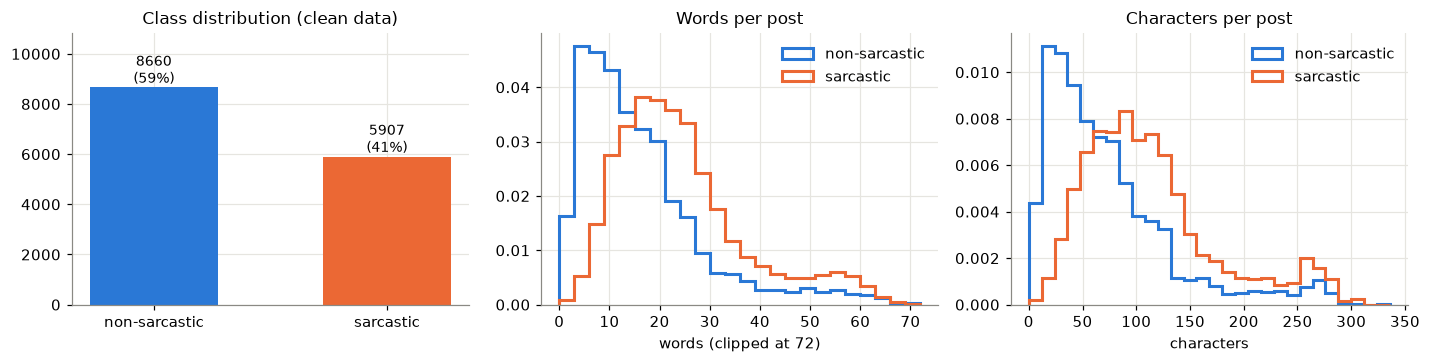

label               0       1
n_chars count  8660.0  5907.0
        mean     71.5   112.5
        std      58.5    62.4
        min       2.0     5.0
        25%      29.0    68.0
        50%      56.0   100.0
        75%      94.0   137.0
        max     327.0   304.0
n_words count  8660.0  5907.0
        mean     15.7    23.9
        std      12.5    13.1
        min       1.0     1.0
        25%       7.0    15.0
        50%      12.0    21.0
        75%      20.0    29.0
        max      70.0    71.0
n_emoji count  8660.0  5907.0
        mean      2.2     1.6
        std       2.7     2.1
        min       0.0     0.0
        25%       1.0     0.0
        50%       2.0     1.0
        75%       3.0     2.0
        max      71.0    42.0

In [8]:
EMOJI_RE = re.compile('(?:[\U0001F1E6-\U0001F1FF]{2}|[\U0001F300-\U0001FAFF☀-➿⬀-⯿⌀-⏿←-⇿〰〽㊗㊙]'
                      '(?:️|[\U0001F3FB-\U0001F3FF])?(?:‍[\U0001F300-\U0001FAFF☀-➿](?:️)?)*)')

eda = data.copy()
eda['n_chars']   = eda.text.str.len()
eda['n_words']   = eda.text.str.split().str.len()
eda['emojis']    = eda.text.map(EMOJI_RE.findall)
eda['n_emoji']   = eda.emojis.str.len()
eda['has_emoji'] = eda.n_emoji > 0
eda['has_latin'] = eda.text.str.contains('[A-Za-z]')
eda['has_url']   = eda.text.str.contains(r'https?://|www\.')
eda['has_mention'] = eda.text.str.contains(r'@\w')
eda['has_hashtag'] = eda.text.str.contains(r'#\w')
eda['has_elong'] = eda.text.str.contains(r'(\w)\1{2,}')
eda['has_quote'] = eda.text.str.contains(r"``|''|\"|“|”")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
cnt = data.label.value_counts().sort_index()
axes[0].bar(['non-sarcastic', 'sarcastic'], cnt.values, color=[C0, C1], width=0.55)
for i, v in enumerate(cnt.values): axes[0].text(i, v, f'{v}\n({v/len(data):.0%})', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Class distribution (clean data)'); axes[0].set_ylim(0, cnt.max() * 1.25)
bins = np.arange(0, 75, 3)
for lab, c, n in [(0, C0, 'non-sarcastic'), (1, C1, 'sarcastic')]:
    axes[1].hist(eda.loc[eda.label == lab, 'n_words'].clip(upper=72), bins=bins, histtype='step', lw=2, color=c, label=n, density=True)
axes[1].set_title('Words per post'); axes[1].set_xlabel('words (clipped at 72)'); axes[1].legend(frameon=False)
bins = np.arange(0, 340, 12)
for lab, c, n in [(0, C0, 'non-sarcastic'), (1, C1, 'sarcastic')]:
    axes[2].hist(eda.loc[eda.label == lab, 'n_chars'], bins=bins, histtype='step', lw=2, color=c, label=n, density=True)
axes[2].set_title('Characters per post'); axes[2].set_xlabel('characters'); axes[2].legend(frameon=False)
plt.tight_layout(); plt.show()

eda.groupby('label')[['n_chars', 'n_words', 'n_emoji']].describe().T.round(1)

In [9]:
# Surface phenomena: prevalence in each class and the sarcasm rate among posts that show the phenomenon
cols = ['has_emoji', 'has_latin', 'has_url', 'has_mention', 'has_hashtag', 'has_elong', 'has_quote']
rows = []
for c in cols:
    rows.append({'phenomenon': c, 'prevalence': eda[c].mean(),
                 'in non-sarcastic': eda.loc[eda.label == 0, c].mean(), 'in sarcastic': eda.loc[eda.label == 1, c].mean(),
                 'P(sarcastic | present)': eda.loc[eda[c], 'label'].mean(), 'P(sarcastic | absent)': eda.loc[~eda[c], 'label'].mean()})
pd.DataFrame(rows).set_index('phenomenon').style.format('{:.1%}')

,prevalence,in non-sarcastic,in sarcastic,P(sarcastic | present),P(sarcastic | absent)
phenomenon,,,,,
has_emoji,79.6%,88.3%,66.8%,34.0%,65.9%
has_latin,15.7%,7.5%,27.6%,71.4%,34.8%
has_url,2.5%,0.3%,5.8%,92.7%,39.2%
has_mention,5.2%,0.9%,11.5%,90.1%,37.9%
has_hashtag,5.0%,0.3%,11.9%,96.4%,37.6%
has_elong,2.7%,3.6%,1.5%,22.4%,41.1%
has_quote,3.7%,2.8%,4.9%,53.9%,40.0%


### Emoji analysis

 As we need to check emojis specifically. Below are the most frequent emojis, how often each appears in sarcastic posts, and the sarcasm rate of semantic **emoji groups**.
The groups are defined in Section 5 and reused as features later.

base rate P(sarcastic) = 40.6%


,emoji,posts,P(sarcastic),group
0,😂,3590,44.2%,LAUGH
1,😜,710,54.2%,LAUGH
2,😁,570,57.0%,LAUGH
3,🤣,492,48.2%,LAUGH
4,💔,415,5.1%,SAD
5,❤,392,9.7%,LOVE
6,🙏,346,30.3%,PRAY
7,❤️,340,9.4%,LOVE
8,😍,319,10.7%,LOVE
9,😅,270,58.9%,LAUGH


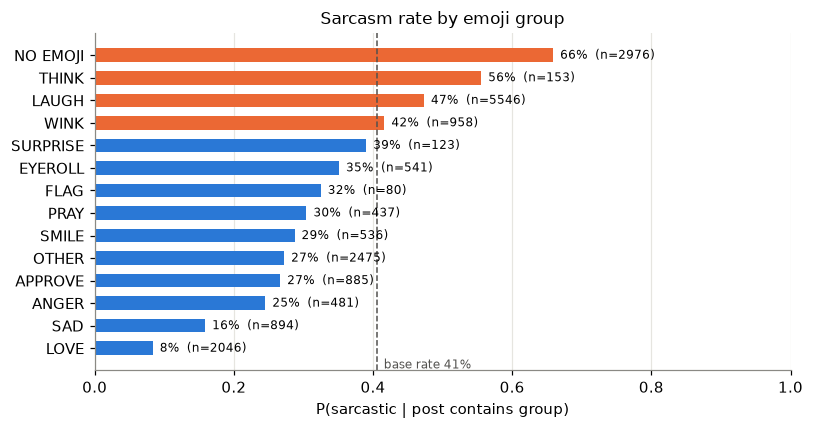

In [10]:
EMO_GROUPS = {
    'LAUGH': '😂🤣😆😅😁😹😄😃😀😝😜😛🤪', 'WINK': '😉😏😎🤭🙊🙈😼', 'EYEROLL': '🙄😒😑😐🤨😶🤦🤷',
    'THINK': '🤔🧐', 'LOVE': '❤♥💕💖💗💓💞😍🥰😘💘🌹🌺💐🌸🌷🥀🍁', 'SAD': '😭😢😥😪😔😞💔😩😫🥺☹😟',
    'ANGER': '😡😠🤬👊🖕💩🔥', 'PRAY': '🙏🤲☝🕋', 'APPROVE': '👍👌👏✌💯✅🙌💪', 'SMILE': '😊🙂☺😇🤗',
    'SURPRISE': '😮😱😳🤯😲😯', 'FLAG': '🇵🇰',
}
EMO2G = {ch: g for g, s in EMO_GROUPS.items() for ch in s}
def emo_group(e): return EMO2G.get(e[0], 'OTHER')

base = data.label.mean()
ec = Counter(); es = Counter()
for em, lab in zip(eda.emojis, eda.label):
    for e in set(em): ec[e] += 1; es[e] += lab
top = pd.DataFrame([{'emoji': e, 'posts': n, 'P(sarcastic)': es[e] / n, 'group': emo_group(e)} for e, n in ec.most_common(20)])
print(f'base rate P(sarcastic) = {base:.1%}')
display(top.style.format({'P(sarcastic)': '{:.1%}'}).background_gradient(subset=['P(sarcastic)'], cmap='Oranges', vmin=0, vmax=1))

g_rows = []
for g in list(EMO_GROUPS) + ['OTHER']:
    m = eda.emojis.map(lambda em: any(emo_group(e) == g for e in em))
    if m.sum() >= 30: g_rows.append((g, m.sum(), eda.loc[m, 'label'].mean()))
g_rows.append(('NO EMOJI', (~eda.has_emoji).sum(), eda.loc[~eda.has_emoji, 'label'].mean()))
gdf = pd.DataFrame(g_rows, columns=['group', 'posts', 'rate']).sort_values('rate')
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(gdf.group, gdf.rate, color=[C1 if r > base else C0 for r in gdf.rate], height=0.6)
ax.axvline(base, color='#52514e', lw=1, ls='--'); ax.text(base + 0.01, -0.9, f'base rate {base:.0%}', fontsize=8, color='#52514e')
for i, (r, n) in enumerate(zip(gdf.rate, gdf.posts)): ax.text(r + 0.01, i, f'{r:.0%}  (n={n})', va='center', fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel('P(sarcastic | post contains group)'); ax.set_title('Sarcasm rate by emoji group')
ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()

**What the emoji statistics show** (exact numbers are in the outputs above):

* Emojis are **not** a simple "😂 = sarcasm" cue. The most frequent emoji, 😂, is only slightly above the 40.6% base rate (44%). Playful faces (😜 54%, 😁 57%, 😉 60%) and 🤔 (55%) are clearer sarcasm cues.
* Surprisingly, the **eye-roll/deadpan group (🙄 😐 😒) is *below* the base rate** (35%; 😐 alone is 28%). These faces mostly express genuine annoyance rather than irony.
* Hearts and flowers (❤️ 🌹, 8% sarcastic), sad faces (💔 😭, 16%) and prayer hands (🙏, 30%) are **non-sarcastic** cues. They mark poetry, religious greetings and condolence posts.
* Posts **without** emojis are *more* often sarcastic than average. Many sarcastic posts are dry political satire scraped from Twitter, with mentions, hashtags and URLs instead of emojis.
* So emoji **identity**, not just emoji presence, is informative. Removing emojis would throw that away, and Section 8 tests this empirically.

In [11]:
# Label-revealing hashtags: an artefact of how the data was collected (hashtag-based distant supervision)
rows = []
for pat in ['#sarcasm', '#satire', '#طنز', 'طنز', 'مزاح', '#']:
    m = data.text.str.contains(re.escape(pat), case=False)
    rows.append({'pattern': pat, 'posts': int(m.sum()), 'share of data': m.mean(), 'P(sarcastic)': data.loc[m, 'label'].mean()})
pd.DataFrame(rows).style.format({'share of data': '{:.1%}', 'P(sarcastic)': '{:.1%}'})

,pattern,posts,share of data,P(sarcastic)
0,#sarcasm,381,2.6%,98.7%
1,#satire,18,0.1%,94.4%
2,#طنز,160,1.1%,100.0%
3,طنز,241,1.7%,99.2%
4,مزاح,419,2.9%,99.5%
5,#,726,5.0%,96.4%


**Label leakage inside the text.** A few percent of posts contain `#sarcasm`, `#satire` or `#طنز` ("satire"), and those posts are essentially always labeled sarcastic.
These tags are **the label written into the input**, left over from hashtag-based data collection. A model that learns "#sarcasm → 1" has learned nothing about sarcasm.
Our main pipeline therefore **masks explicit label hashtags** (`mask_label_tags`, Section 5), and the ablation measures how much they would inflate the scores.

In [12]:
# Most discriminative uni/bi/tri-grams (chi-square on the training-style data); reveals topic confounds
cv_ = CountVectorizer(token_pattern=r'(?u)[^\s]+', ngram_range=(1, 3), min_df=10, binary=True)
M = cv_.fit_transform(data.text.map(lambda t: EMOJI_RE.sub(' ', t)))
s, _ = chi2(M, data.label)
voc = np.array(cv_.get_feature_names_out())
p1 = np.asarray(M[data.label.values == 1].mean(0)).ravel(); p0 = np.asarray(M[data.label.values == 0].mean(0)).ravel()
order = np.argsort(-s)
sar = [v for v in voc[order] if p1[cv_.vocabulary_[v]] > p0[cv_.vocabulary_[v]]][:25]
non = [v for v in voc[order] if p1[cv_.vocabulary_[v]] < p0[cv_.vocabulary_[v]]][:25]
pd.DataFrame({'top sarcastic n-grams': sar, 'top non-sarcastic n-grams': non})

,top sarcastic n-grams,top non-sarcastic n-grams
0,مزاح,اللہ
1,#sarcasm,فالو
2,خان,آمین
3,کے,بیک
4,تنقید,علیہ
5,کی,فالو بیک
6,پر,فالو کریں
7,کا,محبت
8,عمران,جزاک
9,کو,صلی


**Topic confound.** The strongest sarcastic n-grams are political: politician names (عمران خان, نواز شریف, مریم, بلاول, زرداری), party slurs (پٹواری "PML-N supporter", یوتھیا "PTI supporter") and government vocabulary.
The strongest non-sarcastic n-grams are religious formulae (صلی اللہ علیہ وسلم, جزاک اللہ, آمین), follow-back spam (فالو بیک, فالو کریں) and romantic poetry vocabulary (عشق, محبت).
Some of what any classifier learns here is *genre/topic* (political satire vs. religious, poetic or promotional posts) rather than sarcasm as a pragmatic phenomenon.
We keep this in mind for error analysis: non-political sarcasm and sincere political posts should be the hard cases.

In [13]:
print('Representative examples (random, seed fixed):')
ex = pd.concat([data[data.label == 1].sample(5, random_state=1), data[data.label == 0].sample(5, random_state=1)])
ex

Representative examples (random, seed fixed):


,text,label
11612,جس کے سامنے 60 ممالک کا اتحاد نہ ٹک سکا اسکے سامنے تجھ جیسوں کی کیا اوقات ۔۔ تم تو ان کے سامنے مچھر کی حیثیت بھی نہیں رکھتے Markhor,1
6420,پرویز خٹک جب ہوا لگنے نہیں دیتے تھے تو ہم ان کی مجبوری سمجھتے تھے مگر اب تو دھوپ بھی لگنے نہیں دے رہے ہیں..😀😁,1
6190,سچی کہا ہے۔۔اب جاکر کہیں بیچارے کا ویاہ ہوا ہے۔😂😂😂,1
1641,گری ھوٸی پی ٹی آٸی اور گر گٸی 😜🖐,1
13502,سوشل میڈیا پر کچھ جماعتی حضرات اشارتاً اور کچھ کھل کر عمران کی حمایت کرتے نظر آ رہے ہیں. اور باقی جانور مطلب نیوٹرل ہونا ظاہر کر رہے ہیں... #مزاح,1
7758,پھر پارٹی کب ہے 😂😂😂,0
10880,مجاہد نوں دنیا دے ہر بندے دی فکر ہوندی اے 😁 صرف اک مینوں چھڈ کے 😏,0
5920,اوو لڑکی پھوپھو سخت ناراض😈,0
8518,جو تھا۔۔۔۔۔اچھا تھاالحمدللہ جو ہے۔۔۔۔۔بہتر ہےماشااللہ جو ملے گا۔۔۔۔۔بہترین ہوگاانشااللہ,0
3890,جزاک اللہ خیر 🌹,0


**Data-quality issues found**

| Issue | Evidence | Handling |
|---|---|---|
| Missing text or label | about 105 texts and 56 labels missing | rows dropped |
| CSV spill-over columns | `Unnamed: 2..7`, about 17 orphan texts | ignored (cannot be aligned) |
| Duplicates | 4,742 rows (24%) are repeats, 76% of them sarcastic | de-duplicated before splitting |
| Conflicting labels | 646 texts carry both labels | dropped (no gold label) |
| Train/test leakage | naive split puts a large share of test rows verbatim in train | leak-free split on unique texts |
| Label hashtags in text | `#sarcasm`, `#طنز`, `#satire` | masked |
| Class balance shift | 50/50 raw becomes about 59/41 after de-duplication | stratified split, `class_weight='balanced'`, macro-F1 |
| Orthographic variation | Arabic vs. Urdu code points (ي/ی, ك/ک, ه/ہ), diacritics, missing spaces between words | normalization and character n-grams |
| Code-mixing | about 14% of posts contain Latin script (English or Roman-Urdu/Punjabi) | kept; char n-grams and a Latin-ratio feature |
| Social-media noise | URLs, @mentions, elongation (کدووووو), laughter strings (ہاہاہا), scare quotes (`` '') | normalized into marker tokens, **not** deleted |

## 4. Leak-free stratified split (70 / 15 / 15)

In [14]:
train_df, tmp = train_test_split(data, test_size=0.30, stratify=data.label, random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
assert not (set(train_df.text) & set(test_df.text)) and not (set(train_df.text) & set(val_df.text))
for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f'{n:5s}: {len(d):5d} rows | sarcastic share {d.label.mean():.3f}')
y_tr, y_va, y_te = train_df.label.values, val_df.label.values, test_df.label.values
trval_df = pd.concat([train_df, val_df]).reset_index(drop=True)   # used for cross-validated ablations
for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]:   # save the exact splits for reproducibility
    d.to_csv(os.path.join(SAVE_DIR, 'splits', f'{n}.csv'), index=False)

train: 10196 rows | sarcastic share 0.406
val  :  2185 rows | sarcastic share 0.405
test :  2186 rows | sarcastic share 0.405


## 5. Urdu-aware preprocessing

Design principle: **normalize spurious variation, but turn stylistic signals into explicit tokens instead of deleting them.** Each step and why it suits Urdu sarcasm:

| Step | What it does | Why |
|---|---|---|
| Unicode NFC | canonical composition | the same visible word can be stored as different code-point sequences |
| Letter normalization | Arabic ي ى→ی, ك→ک, ه→ہ, ة→ۃ; Arabic-Indic and Urdu digits→ASCII; drop tatweel and zero-width chars | Urdu is often typed on Arabic or Persian keyboards; the same word otherwise splits into several vocabulary entries |
| Diacritics (اعراب) removed | strip harakat (zabar, zer, pesh…) | used inconsistently (mostly in religious text); sparse noise for a bag-of-words model |
| URL / @mention → `URL`, `USER` | replace with placeholders | the specific handle is noise, but the *presence* of a mention signals reply-style Twitter satire |
| `#tag_words` → `HASHTAG tag words` | split underscores | hashtags carry content words (e.g. بزدار کی پرواز) that should match the same words in plain text |
| Label hashtags masked | remove `#sarcasm`, `#satire`, `#طنز`, `#irony` | they leak the label (Section 3) |
| Scare quotes `` '' “ ” → `"` | one symbol | ironic quoting (`` لبرل '') is a classic sarcasm device and should not be split into many variants |
| `!!`/`??` → `!! MULTIPUNCT`; `...`/`…` → `ELLIPSIS` | keep and mark | exaggerated punctuation and trailing ellipses are prosodic cues of irony |
| Elongation `کدووووو` → `کدوو ELONG`; `ہاہاہا` → `LAUGH` | cap repeats at 2 and add a marker | elongation signals mocking intonation; capping lets the stem still match its dictionary form |
| Emojis | configurable: `keep` / `remove` / `tag` (→ `EMO_LAUGH`, `EMO_LOVE`…) / `both` / `only` | tested empirically in Section 8 instead of assumed |

**Tokenization.** Urdu often lacks spaces between words: non-joining letters (ا د ر و …) make words *look* separated, so writers omit the space (e.g. `اوراس پربھونکناہےآپ`).
Whitespace tokenization is therefore incomplete. We combine word n-grams (on whitespace tokens, keeping punctuation, emojis and markers as tokens)
with **character n-grams (`char_wb`, 2–5)**, which recover sub-word stems, affixes (e.g. ـوں, ـیاں) and run-together words without a dedicated Urdu word segmenter.

In [15]:
DIACRITICS = re.compile('[ً-ٰٟۖ-ۭؐ-ؚ]')
CHARMAP = str.maketrans({'ي': 'ی', 'ى': 'ی', 'ك': 'ک', 'ه': 'ہ', 'ة': 'ۃ', 'ـ': '', '​': '', '﻿': '', '‌': '',
                         **{c: str(i) for i, c in enumerate('٠١٢٣٤٥٦٧٨٩')}, **{c: str(i) for i, c in enumerate('۰۱۲۳۴۵۶۷۸۹')}})
LABEL_TAG_RE = re.compile(r'#\s*(sarcasm|sarcastic|satire|irony|طنز|طنزیہ|مزاح)\b', re.I)

def mask_label_tags(t):
    return LABEL_TAG_RE.sub(' ', str(t))

def emo_tag(e):
    return 'EMO_' + emo_group(e)

def preprocess(t, normalize=True, emoji='tag', social=True, elong=True, punct=True, mask=True):
    t = unicodedata.normalize('NFC', str(t))
    if mask:
        t = mask_label_tags(t)
    if normalize:
        t = DIACRITICS.sub('', t.translate(CHARMAP))
    if social:
        t = re.sub(r'https?://\S+|www\.\S+', ' URL ', t)
        t = re.sub(r'@\w+', ' USER ', t)
        t = re.sub(r'#(\w+)', lambda m: ' HASHTAG ' + m.group(1).replace('_', ' '), t)
        t = re.sub(r'(\w)_(\w)', r'\1 \2', t)
    if punct:
        t = re.sub(r"``|''|[“”«»]", ' " ', t)
        t = re.sub(r'([!?؟])\1+', r' \1\1 MULTIPUNCT ', t)
        t = re.sub(r'(\.{2,}|…|۔{2,})', ' ELLIPSIS ', t)
    if elong:
        t = re.sub(r'((?:ہا|ها|ha|Ha|ھا){2,})', ' LAUGH ', t)
        t = re.sub(r'(\w)\1{2,}', r'\1\1 ELONG ', t)
    if emoji == 'remove':
        t = EMOJI_RE.sub(' ', t)
    elif emoji == 'keep':
        t = EMOJI_RE.sub(lambda m: ' ' + m.group(0) + ' ', t)
    elif emoji == 'tag':
        t = EMOJI_RE.sub(lambda m: ' ' + emo_tag(m.group(0)) + ' ', t)
    elif emoji == 'both':
        t = EMOJI_RE.sub(lambda m: ' ' + m.group(0) + ' ' + emo_tag(m.group(0)) + ' ', t)
    elif emoji == 'only':
        t = ' '.join(EMOJI_RE.findall(t)) or 'NOEMOJI'
    return re.sub(r'\s+', ' ', t).strip()

RAW = dict(normalize=False, social=False, elong=False, punct=False, emoji='keep')   # "minimally processed" setting

demo = data.text[data.text.str.contains('ووو|ہاہا|``|#|@|\\.\\.\\.')].sample(5, random_state=3)
pd.DataFrame({'original': demo.values,
              'emoji=keep': [preprocess(t, emoji='keep') for t in demo],
              'emoji=tag (default)': [preprocess(t) for t in demo]})

,original,emoji=keep,emoji=tag (default)
0,حیرت انگیز چیزوں کے بارے میں ایک حیرت انگیز بات تو یہ ہے کہ انہیں دیکھ کر نئی نسل کو بالکل حیرت نہیں ہوتی #صفی #طنز,حیرت انگیز چیزوں کے بارے میں ایک حیرت انگیز بات تو یہ ہے کہ انہیں دیکھ کر نئی نسل کو بالکل حیرت نہیں ہوتی HASHTAG صفی,حیرت انگیز چیزوں کے بارے میں ایک حیرت انگیز بات تو یہ ہے کہ انہیں دیکھ کر نئی نسل کو بالکل حیرت نہیں ہوتی HASHTAG صفی
1,بڑی بھیانک ہوتی ہیں عشق کی سزائیں بندہ پل پل مرتا ہے مگر موت نہیں آتی ... 😕❣❣,بڑی بھیانک ہوتی ہیں عشق کی سزائیں بندہ پل پل مرتا ہے مگر موت نہیں آتی ELLIPSIS 😕 ❣ ❣,بڑی بھیانک ہوتی ہیں عشق کی سزائیں بندہ پل پل مرتا ہے مگر موت نہیں آتی ELLIPSIS EMO_OTHER EMO_OTHER EMO_OTHER
2,ہاۓ چور باپ کی چورنی بیٹی جب تم آپنے پچھواڑے تک کا زور لگاکے کپتان پر تنقید کرتی ہو تو میرے دل گارڈن گارڈن ہوجاتا ہے مزے لیتا ہوں تیری بےبسی دیکھ کر 😉🤣 ابھی...,ہاۓ چور باپ کی چورنی بیٹی جب تم آپنے پچھواڑے تک کا زور لگاکے کپتان پر تنقید کرتی ہو تو میرے دل گارڈن گارڈن ہوجاتا ہے مزے لیتا ہوں تیری بےبسی دیکھ کر 😉 🤣 ابھ...,ہاۓ چور باپ کی چورنی بیٹی جب تم آپنے پچھواڑے تک کا زور لگاکے کپتان پر تنقید کرتی ہو تو میرے دل گارڈن گارڈن ہوجاتا ہے مزے لیتا ہوں تیری بےبسی دیکھ کر EMO_WIN...
3,آج صبح کی عوامی مالی اعانت میں دکھایا گیا ہے کہ حکومت مالی سال کے پہلے نصف حصے میں ریکارڈ اعلی ، 60 سالوں میں سرکاری قرضوں کی بلند ترین سطح اور اس سال خسارہ...,آج صبح کی عوامی مالی اعانت میں دکھایا گیا ہے کہ حکومت مالی سال کے پہلے نصف حصے میں ریکارڈ اعلی ، 60 سالوں میں سرکاری قرضوں کی بلند ترین سطح اور اس سال خسارہ...,آج صبح کی عوامی مالی اعانت میں دکھایا گیا ہے کہ حکومت مالی سال کے پہلے نصف حصے میں ریکارڈ اعلی ، 60 سالوں میں سرکاری قرضوں کی بلند ترین سطح اور اس سال خسارہ...
4,آہاہاہا آپکے ابا کو سچے خواب آتے ہیں 😍,آ LAUGH آپکے ابا کو سچے خواب آتے ہیں 😍,آ LAUGH آپکے ابا کو سچے خواب آتے ہیں EMO_LOVE


## 6. Bonus: hand-crafted Urdu features and phrase detection

**(a) 43 interpretable features** (log-scaled counts) that target theories of sarcasm:

* **Incongruity and contrast** (Riloff et al., 2013): praise words such as واہ, کمال, شاباش, بہت خوب, کیا بات ہے, جی بالکل, ماشاءاللہ appearing *with* a laughing or eye-roll emoji, or positive emojis appearing with insult or negation words.
* **Emoji semantics**: counts per emoji group, a final-emoji flag, repeated-emoji runs (😂😂😂), emoji density.
* **Prosody and typography**: `!` and `?`/`؟` counts, scare quotes, ellipses, elongation, laughter strings.
* **Code-mixing**: Latin-script ratio, Urdu-script ratio, digit ratio.
* **Urdu lexicons** for genre and topic: political figures and party slurs (پٹواری, یوتھیا), religious formulae, follow-back and promotional vocabulary, poetry vocabulary, insults (لفافہ, منافق), negation (نہیں, نہ, مت), question words, intensifiers.

**(b) PMI phrase detection** (Mikolov et al., 2013 phrase score). Bigrams with `(count(ab) − δ)·N / (count(a)·count(b)) > τ` are merged into single tokens, such as `عمران_خان`, `فضل_الرحمن`, `گندے_انڈے` ("rotten eggs", an idiom) and `شب_بخیر`.
This gives the model multi-word expressions and idioms as units. The phrase list is **learned inside each training fold only**, so it cannot leak.

In [16]:
LEX = {
    'praise':      ['واہ', 'کمال', 'شاباش', 'بہت خوب', 'زبردست', 'ماشاءاللہ', 'ماشااللہ', 'جی بالکل', 'اچھا جی', 'ہاں جی', 'کیا بات ہے', 'ویلڈن', 'بلے بلے', 'قربان', 'داد', 'جیو'],
    'politics':    ['عمران', 'نواز', 'شریف', 'زرداری', 'بلاول', 'مریم', 'پٹواری', 'یوتھ', 'حکومت', 'اپوزیشن', 'وزیراعظم', 'لیگ', 'پی ٹی آئی', 'نیازی', 'کپتان', 'صفدر', 'فضل', 'سیاسی', 'pti', 'pmln', 'ppp'],
    'religion':    ['اللہ', 'آمین', 'جزاک', 'سبحان', 'صلی', 'درود', 'نماز', 'رب', 'رمضان', 'دعا', 'الحمد', 'ﷺ', 'استغفر'],
    'promo':       ['فالو', 'ریٹویٹ', 'فالورز', 'مینشن', 'لائک', 'follow', 'retweet'],
    'poetry':      ['دل', 'عشق', 'محبت', 'یاد', 'زندگی', 'آنکھ', 'خواب', 'درد', 'وفا'],
    'negation':    ['نہیں', 'نہ', 'مت', 'نا', 'بغیر'],
    'question':    ['کیا', 'کیوں', 'کیسے', 'کون', 'کب', 'کہاں'],
    'intensifier': ['بہت', 'بالکل', 'انتہائی', 'بڑا', 'بڑی'],
    'insult':      ['گدھا', 'گدھے', 'جاہل', 'بےغیرت', 'بے غیرت', 'لعنت', 'چور', 'ڈاکو', 'منافق', 'کتے', 'بیوقوف', 'لفافہ', 'لفافے'],
}
HAND_NAMES = (['n_chars', 'n_tokens', 'n_emoji', 'emoji_density', 'uniq_emoji', 'emoji_at_end', 'emoji_run3', 'n_excl', 'n_question',
               'n_quotes', 'n_ellipsis', 'n_elong', 'n_laugh_text', 'latin_ratio', 'urdu_ratio', 'digit_ratio', 'has_url', 'has_user', 'has_hashtag']
              + ['emo_' + g for g in EMO_GROUPS] + ['emo_OTHER'] + ['lex_' + k for k in LEX]
              + ['contrast_praise+laugh', 'contrast_posemoji+neg/insult', 'contrast_praise+eyeroll'])
END_EMOJI_RE = re.compile('(?:' + EMOJI_RE.pattern + r')\s*$')
RUN3_RE = re.compile('(' + EMOJI_RE.pattern + r')\1\1')
_TOK_SPLIT = re.compile(r'[\s\.,!?؟۔،"\'()\[\]:;]+')

def lex_count(toks, txt, words):
    # single words matched as whole tokens (so 'نا' does not match inside 'کرنا'); multi-word phrases as substrings
    return sum(txt.count(w) if ' ' in w else toks.count(w) for w in words)

def hand_features(t):
    t = mask_label_tags(unicodedata.normalize('NFC', str(t)).translate(CHARMAP))
    emos = EMOJI_RE.findall(t); txt = EMOJI_RE.sub(' ', t)
    toks = [w for w in _TOK_SPLIT.split(txt.lower()) if w]; L = max(len(t), 1)
    groups = Counter(emo_group(e) for e in emos)
    lex = {k: lex_count(toks, txt.lower(), ws) for k, ws in LEX.items()}
    pos_e = groups['LOVE'] + groups['SMILE'] + groups['APPROVE']; laugh = groups['LAUGH'] + groups['WINK']
    f = [len(t), len(toks), len(emos), len(emos) / max(len(toks), 1), len(set(emos)), int(bool(END_EMOJI_RE.search(t))),
         int(bool(RUN3_RE.search(t))), t.count('!'), t.count('?') + t.count('؟'), len(re.findall(r"``|''|\"|“|”", t)),
         len(re.findall(r'\.{2,}|…|۔{2,}', t)), len(re.findall(r'(\w)\1{2,}', t)), len(re.findall(r'(?:ہا|ha){2,}', t, re.I)),
         len(re.findall('[A-Za-z]', t)) / L, len(re.findall('[؀-ۿ]', t)) / L, len(re.findall(r'\d', t)) / L,
         int('http' in t), int('@' in t), int('#' in t)]
    f += [groups[g] for g in EMO_GROUPS] + [groups['OTHER']] + [lex[k] for k in LEX]
    f += [int(lex['praise'] > 0 and laugh > 0), int(pos_e > 0 and lex['insult'] + lex['negation'] > 0), int(lex['praise'] > 0 and groups['EYEROLL'] > 0)]
    return f

class HandFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): return self
    def transform(self, X): return np.log1p(np.array([hand_features(t) for t in X], dtype=float))
    def get_feature_names_out(self, *a): return np.array(HAND_NAMES)

class PhraseMerger(BaseEstimator, TransformerMixin):
    """Learns collocations on the training data (PMI-style phrase score) and joins them with '_'."""
    def __init__(self, min_count=5, threshold=10.0, pp=None):
        self.min_count, self.threshold, self.pp = min_count, threshold, pp
    def _tok(self, t):
        return (self.pp(t) if self.pp else t).split()
    def fit(self, X, y=None):
        uni, bi = Counter(), Counter()
        for t in X:
            w = self._tok(t); uni.update(w); bi.update(zip(w, w[1:]))
        N = sum(uni.values())
        self.phrases_ = {b for b, c in bi.items()
                         if c >= self.min_count and (c - self.min_count) * N / (uni[b[0]] * uni[b[1]]) > self.threshold
                         and all(re.search(r'[^\W\d_]', x) and not x.isupper() and not EMOJI_RE.search(x) for x in b)}
        return self
    def merge(self, t):
        w = self._tok(t); out = []; i = 0
        while i < len(w):
            if i + 1 < len(w) and (w[i], w[i + 1]) in self.phrases_:
                out.append(w[i] + '_' + w[i + 1]); i += 2
            else:
                out.append(w[i]); i += 1
        return ' '.join(out)
    def transform(self, X): return [self.merge(t) for t in X]

assert len(HAND_NAMES) == len(hand_features('test'))
pm_demo = PhraseMerger(pp=preprocess).fit(train_df.text)
print(f'{len(pm_demo.phrases_)} phrases learned on train, e.g.:')
print(', '.join('_'.join(p) for p in sorted(pm_demo.phrases_)[:40]))

1200 phrases learned on train, e.g.:
_سدا_شاد, آ_رہا, آ_رہی, آ_گئی, آ_گیا, آئ_جی, آئی_ایس, آئی_جی, آئی_ڈی, آئیں_گے, آئے_گا, آئے_گی, آئےناں_کنٹینرتے, آباد_رہیں, آتا_ہے, آتی_ہے, آتے_ہیں, آج_تک, آج_خود, آج_کل, آخر_میں, آخری_خواہش, آر_او, آر_وائی, آر_ٹی, آرمی_چیف, آرہا_ہے, آصف_زرداری, آصف_غفور, آل_محمد, آمد_مرحبا, آمین_ثم, آمین_جزاک, آمین_یا, آن_لائن, آنے_والی, آنے_والے, آپ_نے, آپ_کو, آپ_ﷺ


In [17]:
# Which hand-crafted features separate the classes? (mean value per class and sarcasm rate when the feature fires)
H = pd.DataFrame(np.array([hand_features(t) for t in train_df.text]), columns=HAND_NAMES)
rows = []
for c in HAND_NAMES:
    fires = H[c] > 0
    if fires.sum() >= 40:
        rows.append({'feature': c, 'fires in % of posts': fires.mean(), 'P(sarcastic | fires)': y_tr[fires].mean()})
hf = pd.DataFrame(rows).set_index('feature').sort_values('P(sarcastic | fires)')
print(f'base rate = {y_tr.mean():.1%}')
pd.concat([hf.head(8), hf.tail(10)]).style.format('{:.1%}').background_gradient(subset=['P(sarcastic | fires)'], cmap='RdBu_r', vmin=0, vmax=1)

base rate = 40.6%


,fires in % of posts,P(sarcastic | fires)
feature,,
emo_LOVE,14.0%,8.0%
lex_promo,1.6%,10.1%
lex_religion,6.8%,14.1%
emo_SAD,6.4%,15.4%
contrast_posemoji+neg/insult,4.7%,22.8%
emo_ANGER,3.3%,23.5%
lex_poetry,8.3%,24.9%
emo_APPROVE,6.0%,25.6%
n_quotes,3.6%,54.2%


## Evaluation helpers

Every model goes through the same `evaluate()`: accuracy, per-class precision/recall/F1, macro-F1 and a confusion matrix.
`RESULTS` collects test-set rows for the final table, and `PROBS` keeps validation and test probabilities for the ensemble.

In [18]:
RESULTS, PROBS, PREDS = [], {}, {}

def metrics(y, p):
    pr, rc, f, _ = precision_recall_fscore_support(y, p, labels=[0, 1], zero_division=0)
    return {'accuracy': accuracy_score(y, p), 'P(0)': pr[0], 'R(0)': rc[0], 'F1(0)': f[0],
            'P(1)': pr[1], 'R(1)': rc[1], 'F1(1)': f[1], 'macro-F1': f1_score(y, p, average='macro')}

def record(name, family, val_pred, test_pred, val_prob=None, test_prob=None):
    """Store validation macro-F1 (used for selection) and full test metrics (reported)."""
    val_pred, test_pred = np.asarray(val_pred).astype(int), np.asarray(test_pred).astype(int)
    row = {'model': name, 'family': family, 'val macro-F1': f1_score(y_va, val_pred, average='macro'), **metrics(y_te, test_pred)}
    RESULTS[:] = [r for r in RESULTS if r['model'] != name] + [row]
    PREDS[name] = np.asarray(test_pred).astype(int)
    if val_prob is not None: PROBS[name] = (np.asarray(val_prob), np.asarray(test_prob))
    return row

def results_table(rows=None):
    t = pd.DataFrame(rows or RESULTS).set_index('model')
    return t.style.format({c: '{:.4f}' for c in t.columns if c != 'family'}).highlight_max(subset=['val macro-F1', 'macro-F1'], color='#fde3d4')

def plot_cms(names, ncols=4):
    n = len(names); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.1 * nrows)); axes = np.atleast_1d(axes).ravel()
    for ax, nm in zip(axes, names):
        cm = confusion_matrix(y_te, PREDS[nm], labels=[0, 1])
        ax.imshow(cm, cmap='Blues', vmin=0); ax.grid(False)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f'{cm[i, j]}\n{cm[i, j] / cm[i].sum():.0%}', ha='center', va='center', fontsize=9,
                        color='white' if cm[i, j] > cm.max() * 0.6 else '#0b0b0b')
        ax.set_xticks([0, 1], ['pred 0', 'pred 1']); ax.set_yticks([0, 1], ['true 0', 'true 1'])
        ax.set_title(f'{nm}\nmacro-F1 = {f1_score(y_te, PREDS[nm], average="macro"):.3f}', fontsize=9)
    for ax in axes[n:]: ax.axis('off')
    plt.tight_layout(); plt.show()

def tune_threshold(y, prob):
    ts = np.linspace(0.2, 0.8, 61)
    f = [f1_score(y, prob > t, average='macro') for t in ts]
    return ts[int(np.argmax(f))], max(f)

## 7. Classical TF-IDF baselines

All vectorizers take **raw** text and call `preprocess` themselves. That makes each pipeline self-contained, and in cross-validation every fold is re-fitted from scratch.
`sublinear_tf` dampens repeated tokens (😂😂😂). `class_weight='balanced'` compensates for the 59/41 imbalance, which matters for macro-F1.

In [19]:
TOK = r'(?u)[^\s]+'   # whitespace tokens: keeps emojis, punctuation and marker tokens as features

def W(ngram=(1, 2), **k):
    return TfidfVectorizer(preprocessor=partial(preprocess, **k), token_pattern=TOK, ngram_range=ngram, min_df=2, sublinear_tf=True)
def Ch(**k):
    return TfidfVectorizer(preprocessor=partial(preprocess, **k), analyzer='char_wb', ngram_range=(2, 5), min_df=2,
                           sublinear_tf=True, max_features=300_000)
def WP(**k):
    return make_pipeline(PhraseMerger(pp=partial(preprocess, **k)),
                         TfidfVectorizer(token_pattern=TOK, ngram_range=(1, 2), min_df=2, sublinear_tf=True))
def Hd():
    return make_pipeline(HandFeatures(), MaxAbsScaler())
def LR(C=2.0):
    return LogisticRegression(C=C, max_iter=3000, class_weight='balanced')
def SVC(C=0.3):
    return LinearSVC(C=C, class_weight='balanced')

Xtr, Xva, Xte = train_df.text.values, val_df.text.values, test_df.text.values

In [20]:
# Hyper-parameter search on the validation split (regularization strength)
search = []
for C in [0.5, 1, 2, 4, 8]:
    p = make_pipeline(make_union(W(), Ch()), LR(C)).fit(Xtr, y_tr)
    search.append(('LR word+char', C, f1_score(y_va, p.predict(Xva), average='macro')))
for C in [0.05, 0.1, 0.3, 1]:
    p = make_pipeline(make_union(W(), Ch()), SVC(C)).fit(Xtr, y_tr)
    search.append(('SVM word+char', C, f1_score(y_va, p.predict(Xva), average='macro')))
for a in [0.1, 0.3, 1.0]:
    p = make_pipeline(W(), ComplementNB(alpha=a)).fit(Xtr, y_tr)
    search.append(('ComplementNB word', a, f1_score(y_va, p.predict(Xva), average='macro')))
search = pd.DataFrame(search, columns=['model', 'C / alpha', 'val macro-F1'])
best_hp = search.loc[search.groupby('model')['val macro-F1'].idxmax()].set_index('model')
display(search.pivot_table(index='C / alpha', columns='model', values='val macro-F1').round(4))
best_hp

model,ComplementNB word,LR word+char,SVM word+char
C / alpha,,,
0.05,NaN,NaN,0.7973
0.10,0.7739,NaN,0.7955
0.30,0.7801,NaN,0.7938
0.50,NaN,0.7974,NaN
1.00,0.7911,0.7951,0.7843
2.00,NaN,0.7953,NaN
4.00,NaN,0.7933,NaN
8.00,NaN,0.7879,NaN


,C / alpha,val macro-F1
model,,
ComplementNB word,1.00,0.791110
LR word+char,0.50,0.797412
SVM word+char,0.05,0.797293


In [21]:
C_LR = best_hp.loc['LR word+char', 'C / alpha']; C_SVM = best_hp.loc['SVM word+char', 'C / alpha']; A_NB = best_hp.loc['ComplementNB word', 'C / alpha']

classical = {
    'NB (skeleton: counts, no preprocessing)':      (make_pipeline(CountVectorizer(), MultinomialNB()), False),
    'ComplementNB  word 1-2':                        (make_pipeline(W(), ComplementNB(alpha=A_NB)), False),
    'LR  word 1-2':                                  (make_pipeline(W(), LR(C_LR)), True),
    'LR  char 2-5':                                  (make_pipeline(Ch(), LR(C_LR)), True),
    'LR  word+char':                                 (make_pipeline(make_union(W(), Ch()), LR(C_LR)), True),
    'SVM word+char':                                 (make_pipeline(make_union(W(), Ch()), SVC(C_SVM)), False),
    'LR  hand-crafted only (43 feats)':              (make_pipeline(Hd(), LR(1.0)), True),
    'LR  phrase-word+char+hand (bonus)':             (make_pipeline(make_union(WP(), Ch(), Hd()), LR(C_LR)), True),
    'SVM phrase-word+char+hand (bonus)':             (make_pipeline(make_union(WP(), Ch(), Hd()), SVC(C_SVM)), False),
}
fitted = {}
for name, (pipe, has_proba) in classical.items():
    t = time.time(); pipe.fit(Xtr, y_tr); fitted[name] = pipe
    pv, pt = pipe.predict(Xva), pipe.predict(Xte)
    probs = (pipe.predict_proba(Xva)[:, 1], pipe.predict_proba(Xte)[:, 1]) if has_proba else (None, None)
    r = record(name, 'classical', pv, pt, *probs)
    print(f'{name:45s} val {r["val macro-F1"]:.4f} | test {r["macro-F1"]:.4f}  ({time.time() - t:.0f}s)')

NB (skeleton: counts, no preprocessing)       val 0.7917 | test 0.7926  (0s)


ComplementNB  word 1-2                        val 0.7911 | test 0.8022  (1s)


LR  word 1-2                                  val 0.7750 | test 0.7921  (1s)


LR  char 2-5                                  val 0.7954 | test 0.8181  (2s)


LR  word+char                                 val 0.7974 | test 0.8182  (3s)


SVM word+char                                 val 0.7973 | test 0.8208  (2s)


LR  hand-crafted only (43 feats)              val 0.7637 | test 0.7633  (1s)


LR  phrase-word+char+hand (bonus)             val 0.8096 | test 0.8239  (4s)


SVM phrase-word+char+hand (bonus)             val 0.8092 | test 0.8239  (3s)


In [22]:
# Most influential features of the best interpretable model (LR, phrase-word + char + hand)
lr_best = fitted['LR  phrase-word+char+hand (bonus)']
union, clf = lr_best.steps[0][1], lr_best.steps[1][1]
names = np.concatenate([
    ['w:' + v for v in union.transformer_list[0][1].steps[1][1].get_feature_names_out()],
    ['c:' + v for v in union.transformer_list[1][1].get_feature_names_out()],
    ['h:' + v for v in HAND_NAMES]])
coef = clf.coef_.ravel()
o = np.argsort(coef)
pd.DataFrame({'→ non-sarcastic': names[o[:25]], 'w0': coef[o[:25]].round(2),
              '→ sarcastic': names[o[::-1][:25]], 'w1': coef[o[::-1][:25]].round(2)})

,→ non-sarcastic,w0,→ sarcastic,w1
0,h:lex_religion,-1.99,h:emo_LAUGH,2.63
1,h:lex_promo,-1.89,h:n_chars,2.39
2,h:emo_LOVE,-1.87,h:lex_politics,2.19
3,h:emoji_density,-1.57,h:n_tokens,2.05
4,h:lex_poetry,-1.31,h:has_user,1.66
5,w:emo_love,-1.10,h:has_hashtag,1.62
6,w:جی,-0.86,h:has_url,1.41
7,h:n_emoji,-0.85,w:مزاح,1.21
8,w:میری,-0.80,h:lex_insult,1.19
9,w:emo_wink emo_laugh,-0.79,h:emo_WINK,1.17


## 8. Ablation study (5-fold stratified CV on train+val)

A single 2.2k-example validation split has a standard error of about ±0.01 macro-F1, which is as large as most preprocessing effects.
Each configuration is therefore evaluated with **5-fold stratified cross-validation on train+val**, using the **same folds** for every configuration.
That allows *paired* comparisons: Δ is the per-fold difference to the reference configuration, and "wins" counts the folds where the variant beats the reference.
The test set is not touched.

Reference configuration: full preprocessing, `emoji='tag'`, word (1–2) + char (2–5) TF-IDF, logistic regression.

In [23]:
Xcv, ycv = trval_df.text.values, trval_df.label.values
FOLDS = StratifiedKFold(5, shuffle=True, random_state=SEED)
def cv_scores(feats, clf=None):
    return cross_val_score(make_pipeline(feats, clf or LR(C_LR)), Xcv, ycv, cv=FOLDS, scoring='f1_macro', n_jobs=5)

ABL = [  # (ablation group, configuration, feature-builder)
    ('Emoji handling', 'emoji = tag  [reference]',             lambda: make_union(W(), Ch())),
    ('Emoji handling', 'emoji = keep (raw emoji tokens)',       lambda: make_union(W(emoji='keep'), Ch(emoji='keep'))),
    ('Emoji handling', 'emoji = both (emoji + tag)',            lambda: make_union(W(emoji='both'), Ch(emoji='both'))),
    ('Emoji handling', 'emoji = remove',                        lambda: make_union(W(emoji='remove'), Ch(emoji='remove'))),
    ('Emoji handling', 'emojis ONLY (all text deleted)',        lambda: W(emoji='only')),
    ('Normalization',  'minimally processed text',              lambda: make_union(W(**RAW), Ch(**RAW))),
    ('Normalization',  'letter normalization only',             lambda: make_union(W(**{**RAW, 'normalize': True}), Ch(**{**RAW, 'normalize': True}))),
    ('Normalization',  'full minus elongation/laugh markers',   lambda: make_union(W(elong=False), Ch(elong=False))),
    ('Normalization',  'full minus punctuation markers',        lambda: make_union(W(punct=False), Ch(punct=False))),
    ('Normalization',  'full minus URL/USER/hashtag handling',  lambda: make_union(W(social=False), Ch(social=False))),
    ('Features',       'word 1-2 only',                         lambda: W()),
    ('Features',       'word 1 only (unigrams)',                lambda: W(ngram=(1, 1))),
    ('Features',       'char_wb 2-5 only',                      lambda: Ch()),
    ('Features',       'hand-crafted only',                     lambda: Hd()),
    ('Features',       'word+char + hand-crafted',              lambda: make_union(W(), Ch(), Hd())),
    ('Features',       'phrase-word + char',                    lambda: make_union(WP(), Ch())),
    ('Features',       'phrase-word + char + hand-crafted',     lambda: make_union(WP(), Ch(), Hd())),
    ('Leakage check',  'label hashtags NOT masked',             lambda: make_union(W(mask=False), Ch(mask=False))),
]
abl_rows, ref = [], None
for g, name, fb in ABL:
    s = cv_scores(fb())
    if ref is None: ref = s
    abl_rows.append({'group': g, 'configuration': name, 'CV macro-F1': s.mean(), 'std': s.std(),
                     'Δ vs ref': (s - ref).mean(), 'wins/5': int((s > ref).sum())})
    print(f'{g:15s} | {name:40s} {s.mean():.4f} ± {s.std():.4f}')
abl = pd.DataFrame(abl_rows)
abl.style.format({'CV macro-F1': '{:.4f}', 'std': '{:.4f}', 'Δ vs ref': '{:+.4f}'}).bar(subset=['Δ vs ref'], align='zero', color=['#9ec5f0', '#f6b89c'])

Emoji handling  | emoji = tag  [reference]                 0.8105 ± 0.0055


Emoji handling  | emoji = keep (raw emoji tokens)          0.8127 ± 0.0059


Emoji handling  | emoji = both (emoji + tag)               0.8098 ± 0.0059


Emoji handling  | emoji = remove                           0.8090 ± 0.0059


Emoji handling  | emojis ONLY (all text deleted)           0.6573 ± 0.0051


Normalization   | minimally processed text                 0.8045 ± 0.0071


... (9 outputs left out)

Features        | phrase-word + char                       0.8103 ± 0.0036


Features        | phrase-word + char + hand-crafted        0.8136 ± 0.0046


Leakage check   | label hashtags NOT masked                0.8147 ± 0.0051


,group,configuration,CV macro-F1,std,Δ vs ref,wins/5
0,Emoji handling,emoji = tag [reference],0.8105,0.0055,+0.0000,0
1,Emoji handling,emoji = keep (raw emoji tokens),0.8127,0.0059,+0.0022,4
2,Emoji handling,emoji = both (emoji + tag),0.8098,0.0059,-0.0007,1
3,Emoji handling,emoji = remove,0.8090,0.0059,-0.0015,2
4,Emoji handling,emojis ONLY (all text deleted),0.6573,0.0051,-0.1531,0
5,Normalization,minimally processed text,0.8045,0.0071,-0.0060,0
6,Normalization,letter normalization only,0.8058,0.0067,-0.0047,1
7,Normalization,full minus elongation/laugh markers,0.8100,0.0060,-0.0005,1
8,Normalization,full minus punctuation markers,0.8116,0.0070,+0.0011,3
9,Normalization,full minus URL/USER/hashtag handling,0.8059,0.0055,-0.0045,1


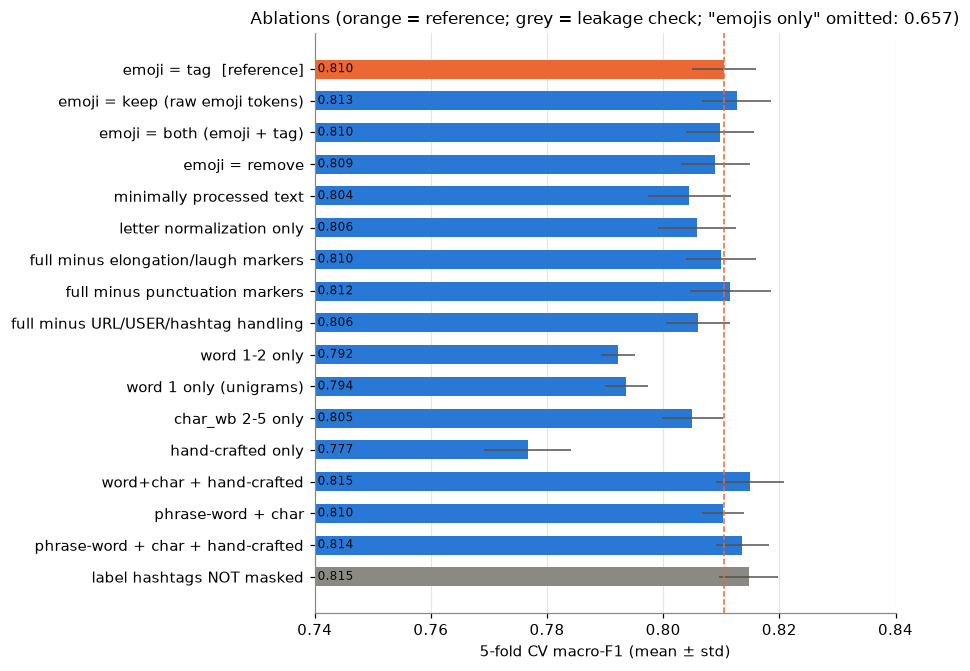

In [24]:
a = abl[abl.configuration != 'emojis ONLY (all text deleted)'].iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 6.2))
cols = [C1 if 'reference' in c else ('#8a8984' if g == 'Leakage check' else C0) for c, g in zip(a.configuration, a.group)]
ax.barh(a.configuration, a['CV macro-F1'], xerr=a['std'], color=cols, height=0.6, error_kw=dict(lw=1, ecolor='#52514e'))
ax.axvline(abl.iloc[0]['CV macro-F1'], color=C1, lw=1, ls='--')
for i, v in enumerate(a['CV macro-F1']): ax.text(0.7405, i, f'{v:.3f}', va='center', fontsize=8, color='#0b0b0b')
ax.set_xlim(0.74, 0.84); ax.set_xlabel('5-fold CV macro-F1 (mean ± std)'); ax.grid(axis='y', visible=False)
ax.set_title('Ablations (orange = reference; grey = leakage check; "emojis only" omitted: %.3f)' % abl.loc[abl.configuration.str.startswith('emojis ONLY'), 'CV macro-F1'].iloc[0])
plt.tight_layout(); plt.show()

**Ablation findings.** Numbers are 5-fold CV macro-F1. Δ is relative to the reference; *wins/5* counts the folds where the variant beats the reference.

**Emoji handling.**
* Keeping raw emoji tokens is the best text setting (0.8127, beating the reference in 4 of 5 folds).
* Semantic tags (0.8105) and raw emoji plus tag (0.8098) come next. **Removing emojis is the worst text setting (0.8090).**
* The differences between text settings are small (≤ 0.004, about one standard deviation), because emoji information in this dataset is **largely redundant with the words**. For example, political satire is recognizable from its vocabulary whether or not it ends in 😂.
* Emojis are not useless, though. **Emojis alone, with every word deleted, reach 0.657 macro-F1**, compared with about 0.37 for majority-class prediction. Section 13 also shows that trained models change many predictions when emojis are removed at test time.
* Semantic grouping did not beat raw emojis. With 10k training posts there is enough data to learn a weight for each frequent emoji, and our groups merge emojis that behave differently (e.g. 😂 is 44% sarcastic, 😉 60%, and 🙈 only 29%).
* **Conclusion:** keep emojis. Raw tokens are the simplest and best choice for TF-IDF, and removing emojis is never better.

**Normalization.**
* Full preprocessing beats minimally processed text by +0.006, winning in **all 5 folds**.
* Letter normalization alone gives only +0.001, because char n-grams already absorb most Arabic-vs-Urdu code-point variants.
* The largest single contribution is the **URL / @mention / hashtag handling**: disabling it costs −0.0045. Mentions and links mark the Twitter reply genre in which most of the satire occurs.
* Elongation and laughter markers are neutral (−0.0005). They are rare: only 2.7% of posts have elongation.
* Punctuation markers did not help (+0.001 when removed). Our hypothesis that `!!`, ellipses and scare quotes are useful cues is **not supported** for this data.

**Feature types.**
* Character n-grams (0.805) beat word n-grams (0.792), as expected for Urdu with its missing spaces and spelling variation. The union is better than either (0.8105).
* Adding the 43 hand-crafted features gives **+0.0045, winning in all 5 folds**.
* PMI phrases on their own are neutral (−0.0002): most collocations are already captured by word bigrams. They help slightly in combination with the hand-crafted features (+0.0031, 5/5).
* The hand-crafted features alone reach 0.777, close to word n-grams with a vocabulary of over 100k features.

**Leakage check.** Not masking `#sarcasm` / `#طنز` raises CV macro-F1 by +0.0043 in all 5 folds. This gain is spurious, because the model is reading the annotation, so all reported models use the masked text.

## 9. Neural models (PyTorch, trained from scratch)

Two complementary architectures:

* **BiGRU + additive attention + max-pooling (word level).** The recurrent layer reads the post in order, which matters for sarcasm's typical *setup → twist* structure (praise followed by a contradicting clause or emoji).
  Attention lets the model focus on the few tokens that carry the irony. Input tokens are the preprocessed text with `emoji='both'`, so the network sees both the raw emoji and its semantic tag.
* **Multi-width char-CNN (kernels 2–6).** Convolutions over characters learn the same sub-word patterns as char n-grams, but as dense, shared filters.
  This makes it robust to Urdu spelling variation, run-together words and Roman-Urdu code-mixing, where a word vocabulary breaks down.

Training: AdamW, class-weighted cross-entropy (for the imbalance), dropout, gradient clipping, 10 epochs, and selection of the **epoch with the best validation macro-F1** (early stopping).
The best-epoch weights are saved to `artifacts/models/` and re-used on later runs. This also makes results identical across runs, because GPU (MPS) training is not bit-for-bit deterministic. Set `FORCE_RETRAIN_NN = True` to train again.

In [25]:
NN_PP = partial(preprocess, emoji='both')

def make_encoder(vocab, level):
    tok = (lambda s: list(s)) if level == 'char' else (lambda s: s.split())
    max_len = 300 if level == 'char' else 64
    def encode(texts):
        return torch.tensor([([vocab.get(w, 1) for w in tok(NN_PP(s))][:max_len] + [0] * max_len)[:max_len] for s in texts])
    return encode

def build_vocab(level, min_count=2):
    tok = (lambda s: list(s)) if level == 'char' else (lambda s: s.split())
    c = Counter(w for s in train_df.text for w in tok(NN_PP(s)))
    vocab = {w: i + 2 for i, (w, n) in enumerate(c.most_common()) if n >= min_count}   # 0 = PAD, 1 = UNK
    return vocab, make_encoder(vocab, level)

class BiGRUAttention(nn.Module):
    def __init__(self, V, E=200, H=128, p=0.4):
        super().__init__()
        self.emb = nn.Embedding(V, E, padding_idx=0); self.drop = nn.Dropout(p)
        self.rnn = nn.GRU(E, H, batch_first=True, bidirectional=True)
        self.att = nn.Linear(2 * H, 1); self.out = nn.Linear(4 * H, 2)
    def forward(self, x):
        mask = x > 0
        h, _ = self.rnn(self.drop(self.emb(x)))
        a = self.att(h).squeeze(-1).masked_fill(~mask, -1e9).softmax(-1)
        ctx = (a.unsqueeze(-1) * h).sum(1)
        mx = h.masked_fill(~mask.unsqueeze(-1), -1e9).max(1).values
        return self.out(self.drop(torch.cat([ctx, mx], -1)))

class CharCNN(nn.Module):
    def __init__(self, V, E=64, F=128, widths=(2, 3, 4, 5, 6), p=0.5):
        super().__init__()
        self.emb = nn.Embedding(V, E, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(E, F, k, padding=k // 2) for k in widths])
        self.drop = nn.Dropout(p); self.out = nn.Linear(len(widths) * F, 2)
    def forward(self, x):
        e = self.emb(x).transpose(1, 2)
        return self.out(self.drop(torch.cat([torch.relu(c(e)).max(-1).values for c in self.convs], -1)))

def train_nn(model, Xtr_t, Xva_t, Xte_t, epochs=2 if SMOKE else 10, lr=2e-3, bs=64, device='cpu'):
    set_seed(); model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    w = torch.tensor([1.0, (y_tr == 0).sum() / (y_tr == 1).sum()], dtype=torch.float, device=device)
    lossf = nn.CrossEntropyLoss(weight=w); y = torch.tensor(y_tr, device=device)
    g = torch.Generator().manual_seed(SEED)
    def predict(X):
        model.eval()
        with torch.no_grad():
            return torch.cat([model(X[i:i + 512].to(device)).softmax(-1)[:, 1].cpu() for i in range(0, len(X), 512)]).numpy()
    best, hist, best_state = (-1, None, None, -1), [], None
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr_t), generator=g); t = time.time()
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            loss = lossf(model(Xtr_t[b].to(device)), y[b.to(device)])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        pv = predict(Xva_t); f = f1_score(y_va, pv > 0.5, average='macro'); hist.append(f)
        print(f'  epoch {ep + 1:2d}: val macro-F1 {f:.4f}  ({time.time() - t:.0f}s)')
        if f > best[0]:
            best = (f, pv, predict(Xte_t), ep + 1)
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)   # keep the best-epoch weights
    return best, hist

nn_hist = {}
for name, level, Model, dev in [('BiGRU+attention (word)', 'word', BiGRUAttention, 'cpu'),
                                ('Char-CNN (multi-width)', 'char', CharCNN, DEVICE)]:
    ck_path = os.path.join(SAVE_DIR, ('bigru_word' if level == 'word' else 'charcnn') + '.pt')
    ck = torch.load(ck_path, weights_only=False) if os.path.exists(ck_path) and not FORCE_RETRAIN_NN else None
    if ck is not None and 'hist' in ck:   # re-use saved best-epoch weights (fast, and identical results on every run)
        vocab, enc = ck['vocab'], make_encoder(ck['vocab'], level)
        model = Model(len(vocab) + 2); model.load_state_dict(ck['state_dict']); model.eval()
        with torch.no_grad():
            pv, pt = [torch.cat([model(X[i:i + 512]).softmax(-1)[:, 1] for i in range(0, len(X), 512)]).numpy()
                      for X in (enc(val_df.text), enc(test_df.text))]
        ep, nn_hist[name] = ck['best_epoch'], ck['hist']; f = f1_score(y_va, pv > 0.5, average='macro')
        print(f'{name}: loaded saved weights ({ck_path})')
    else:
        vocab, enc = build_vocab(level)
        print(f'{name}: vocab = {len(vocab)} | device = {dev}')
        model = Model(len(vocab) + 2)
        (f, pv, pt, ep), nn_hist[name] = train_nn(model, enc(train_df.text), enc(val_df.text), enc(test_df.text), device=dev)
        torch.save({'state_dict': model.cpu().state_dict(), 'vocab': vocab, 'level': level, 'class': Model.__name__,
                    'best_epoch': ep, 'hist': nn_hist[name]}, ck_path)
    record(name, 'neural', pv > 0.5, pt > 0.5, pv, pt)
    print(f'  -> best epoch {ep}, val {f:.4f}, test macro-F1 {f1_score(y_te, pt > 0.5, average="macro"):.4f}\n')

BiGRU+attention (word): loaded saved weights (artifacts/models/bigru_word.pt)
  -> best epoch 4, val 0.7938, test macro-F1 0.8006



Char-CNN (multi-width): loaded saved weights (artifacts/models/charcnn.pt)
  -> best epoch 6, val 0.7872, test macro-F1 0.8060



## 10. Transformer fine-tuning

Models are chosen for *Urdu social-media* text. All three are pretrained on Urdu among other languages, and differ in domain and in how they treat emojis and Romanized text:

| Model | Pretraining | Why it fits |
|---|---|---|
| **XLM-T** `cardiffnlp/twitter-xlm-roberta-base` (Barbieri et al., 2022) | XLM-R base (CC-100, 100 languages incl. Urdu) **further pretrained on 198M multilingual tweets** | in-domain: informal Twitter language, hashtags, mentions, emojis |
| **TwHIN-BERT** `Twitter/twhin-bert-base` (Zhang et al., 2023) | 7B tweets in 100+ languages, with a social-engagement objective | in-domain, multilingual, emoji-aware vocabulary |
| **MuRIL** `google/muril-base-cased` (Khanuja et al., 2021) | 17 Indian languages incl. Urdu, **plus transliterated (Romanized) text** | South-Asian focus; handles Roman-Urdu code-mixing |

Setup: max length 128 sub-words (covers more than 99% of posts), batch 16, AdamW, linear warm-up (10%) and decay, 4 epochs, best epoch chosen by validation macro-F1.
Input is lightly preprocessed: label tags masked, URL/USER placeholders, letter normalization. **Emojis are kept raw.** The coverage check below shows that XLM-T and TwHIN-BERT have tokens for almost every emoji in the data, while **MuRIL maps all of them to `[UNK]`**: its WordPiece vocabulary was built from Indic-language text without emojis. Comparing MuRIL with the other two is therefore also a comparison between emoji-aware and emoji-blind models.
Predictions are cached in `artifacts/` so the notebook can be re-run without re-training (`FORCE_RETRAIN_TRANSFORMERS`).

In [26]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

TRANSFORMERS = [('XLM-T (twitter-xlm-roberta-base)', 'cardiffnlp/twitter-xlm-roberta-base', 2e-5),
                ('TwHIN-BERT base',                  'Twitter/twhin-bert-base',             2e-5),
                ('MuRIL base',                       'google/muril-base-cased',             3e-5)]
def model_path(hf_id):
    local = os.path.join(HF_LOCAL, hf_id.replace('/', '__'))
    return local if os.path.isdir(local) else hf_id

TF_PP = partial(preprocess, emoji='keep', elong=False, punct=False)

# Emoji coverage of each tokenizer: does the model even *see* emojis, or are they mapped to [UNK]?
all_emojis = Counter(e for em in eda.emojis for e in em)
top_emojis = [e for e, _ in all_emojis.most_common(100)]
cov = []
for nm, hf_id, _ in TRANSFORMERS:
    tk = AutoTokenizer.from_pretrained(model_path(hf_id))
    ids = tk(top_emojis, add_special_tokens=False)['input_ids']
    unk = [e for e, i in zip(top_emojis, ids) if tk.unk_token_id in i]
    weight_unk = sum(all_emojis[e] for e in unk) / sum(all_emojis[e] for e in top_emojis)
    lens = [len(tk(t, truncation=False)['input_ids']) for t in train_df.text.sample(min(2000, len(train_df)), random_state=0).map(TF_PP)]
    cov.append({'model': nm, 'top-100 emojis → UNK': len(unk), 'share of emoji occurrences lost': weight_unk,
                'example UNK emojis': ' '.join(unk[:12]), 'mean sub-words/post': np.mean(lens), '% posts > 128': np.mean(np.array(lens) > 128)})
pd.DataFrame(cov).set_index('model').style.format({'share of emoji occurrences lost': '{:.1%}', 'mean sub-words/post': '{:.1f}', '% posts > 128': '{:.2%}'})

,top-100 emojis → UNK,share of emoji occurrences lost,example UNK emojis,mean sub-words/post,% posts > 128
model,,,,,
XLM-T (twitter-xlm-roberta-base),4,0.8%,🔄 🐕 🌚 🐅,31.7,0.05%
TwHIN-BERT base,4,0.8%,🔄 🐕 🌚 🐅,31.7,0.05%
MuRIL base,100,100.0%,😂 😜 🤣 😁 ❤ 🙏 💔 ❤️ 🌹 😍 😝 😅,28.1,0.05%


In [27]:
def finetune(nm, hf_id, lr, epochs=1 if SMOKE else 4, max_len=128, bs=16):
    cache = os.path.join(ART, hf_id.replace('/', '__') + '.npz')
    if os.path.exists(cache) and not FORCE_RETRAIN_TRANSFORMERS:
        z = np.load(cache, allow_pickle=True); print(f'{nm}: loaded cached predictions ({cache})')
        return z['val'], z['test'], z['test_noemo'], list(z['hist']), int(z['best_ep'])
    set_seed(); torch.mps.manual_seed(SEED) if DEVICE == 'mps' else None
    tok = AutoTokenizer.from_pretrained(model_path(hf_id))
    model = AutoModelForSequenceClassification.from_pretrained(model_path(hf_id), num_labels=2).to(DEVICE)
    def enc(d):
        e = tok([TF_PP(t) for t in d.text], truncation=True, max_length=max_len)
        return [{'input_ids': a, 'attention_mask': m, 'labels': int(l)} for a, m, l in zip(e['input_ids'], e['attention_mask'], d.label)]
    collate = lambda b: tok.pad(b, return_tensors='pt')
    g = torch.Generator().manual_seed(SEED)
    dl_tr = torch.utils.data.DataLoader(enc(train_df), bs, shuffle=True, collate_fn=collate, generator=g)
    dl_va = torch.utils.data.DataLoader(enc(val_df), 64, collate_fn=collate)
    dl_te = torch.utils.data.DataLoader(enc(test_df), 64, collate_fn=collate)
    test_ne = test_df.assign(text=test_df.text.map(lambda t: re.sub(r'\s+', ' ', EMOJI_RE.sub(' ', t)).strip()))
    dl_tn = torch.utils.data.DataLoader(enc(test_ne), 64, collate_fn=collate)   # emoji-deleted test copy (Section 13)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * len(dl_tr) * epochs), len(dl_tr) * epochs)
    def predict(dl):
        model.eval(); out = []
        with torch.no_grad():
            for b in dl:
                b = {k: v.to(DEVICE) for k, v in b.items()}
                out.append(torch.softmax(model(**b).logits.float(), -1)[:, 1].cpu())
        model.train(); return torch.cat(out).numpy()
    best, hist = (-1, None, None, None, -1), []
    model.train()
    for ep in range(epochs):
        t = time.time()
        for b in dl_tr:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            model(**b).loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sch.step(); opt.zero_grad()
        pv = predict(dl_va); f = f1_score(y_va, pv > 0.5, average='macro'); hist.append(f)
        print(f'  {nm} epoch {ep + 1}: val macro-F1 {f:.4f}  ({time.time() - t:.0f}s)')
        if f > best[0]:
            best = (f, pv, predict(dl_te), predict(dl_tn), ep + 1)
            if SAVE_TRANSFORMER_WEIGHTS:   # best-epoch fine-tuned checkpoint, reusable with from_pretrained()
                out = os.path.join(SAVE_DIR, 'transformers', hf_id.replace('/', '__'))
                model.save_pretrained(out); tok.save_pretrained(out)
    np.savez(cache, val=best[1], test=best[2], test_noemo=best[3], hist=np.array(hist), best_ep=best[4])
    del model; torch.mps.empty_cache() if DEVICE == 'mps' else None
    return best[1], best[2], best[3], hist, best[4]

tf_hist, TF_NOEMO = {}, {}
for nm, hf_id, lr in TRANSFORMERS:
    pv, pt, TF_NOEMO[nm], tf_hist[nm], ep = finetune(nm, hf_id, lr)
    record(nm, 'transformer', pv > 0.5, pt > 0.5, pv, pt)
    print(f'-> {nm}: best epoch {ep}, val {f1_score(y_va, pv > .5, average="macro"):.4f}, test {f1_score(y_te, pt > .5, average="macro"):.4f}\n')

XLM-T (twitter-xlm-roberta-base): loaded cached predictions (artifacts/cardiffnlp__twitter-xlm-roberta-base.npz)
-> XLM-T (twitter-xlm-roberta-base): best epoch 3, val 0.8165, test 0.8297

TwHIN-BERT base: loaded cached predictions (artifacts/Twitter__twhin-bert-base.npz)
-> TwHIN-BERT base: best epoch 3, val 0.8161, test 0.8319

MuRIL base: loaded cached predictions (artifacts/google__muril-base-cased.npz)
-> MuRIL base: best epoch 2, val 0.8138, test 0.8217



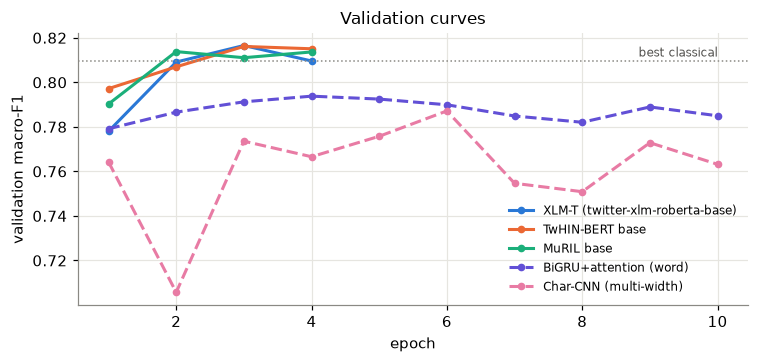

In [28]:
fig, ax = plt.subplots(figsize=(7, 3.4))
styles = {**{k: ('-', c) for k, c in zip(tf_hist, ['#2a78d6', '#eb6834', '#1baf7a'])}, **{k: ('--', c) for k, c in zip(nn_hist, ['#6250d6', '#e87ba4'])}}
for k, h in {**tf_hist, **nn_hist}.items():
    ls, c = styles[k]; ax.plot(range(1, len(h) + 1), h, ls, color=c, lw=2, marker='o', ms=4, label=k)
best_cl = max(r['val macro-F1'] for r in RESULTS if r['family'] == 'classical')
ax.axhline(best_cl, color='#8a8984', lw=1, ls=':'); ax.text(10, best_cl + 0.002, 'best classical', ha='right', fontsize=8, color='#52514e')
ax.set_xlabel('epoch'); ax.set_ylabel('validation macro-F1'); ax.set_title('Validation curves'); ax.legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

## 11. Ensemble

The model families make different errors: TF-IDF memorizes lexical and topical cues, the char-CNN learns orthographic patterns, and transformers bring pretrained semantics.
We average their predicted probabilities. **Weights and the decision threshold are chosen on the validation split only**, using a coarse grid over the top-performing models.

In [29]:
cands = sorted(PROBS, key=lambda k: -f1_score(y_va, PROBS[k][0] > 0.5, average='macro'))[:5]
print('candidate members (by val macro-F1):', cands)
import itertools
best_ens = (-1, None, None)
grid = [0, 1, 2, 3]
for w in itertools.product(grid[:2] if SMOKE else grid, repeat=len(cands)):
    if sum(w) == 0: continue
    pv = sum(wi * PROBS[k][0] for wi, k in zip(w, cands)) / sum(w)
    th, f = tune_threshold(y_va, pv)
    if f > best_ens[0] + 1e-9: best_ens = (f, w, th)
f, w, th = best_ens
weights = {k: wi / sum(w) for k, wi in zip(cands, w) if wi}
print('weights:', {k: round(v, 2) for k, v in weights.items()}, '| threshold', round(th, 3), '| val macro-F1', round(f, 4))
ens_va = sum(v * PROBS[k][0] for k, v in weights.items()); ens_te = sum(v * PROBS[k][1] for k, v in weights.items())
record('Ensemble (weighted avg, val-tuned)', 'ensemble', ens_va > th, ens_te > th, ens_va, ens_te)

# simpler, untuned alternative: equal-weight average of the best transformer + best classical, threshold 0.5
best_tf = max([r for r in RESULTS if r['family'] == 'transformer'], key=lambda r: r['val macro-F1'])['model']
best_clp = max([r for r in RESULTS if r['family'] == 'classical' and r['model'] in PROBS], key=lambda r: r['val macro-F1'])['model']
s_va = (PROBS[best_tf][0] + PROBS[best_clp][0]) / 2; s_te = (PROBS[best_tf][1] + PROBS[best_clp][1]) / 2
record(f'Ensemble (equal: best transformer + best classical)', 'ensemble', s_va > 0.5, s_te > 0.5, s_va, s_te)
print('best transformer:', best_tf, '| best classical (probabilistic):', best_clp)

candidate members (by val macro-F1): ['XLM-T (twitter-xlm-roberta-base)', 'TwHIN-BERT base', 'MuRIL base', 'LR  phrase-word+char+hand (bonus)', 'LR  word+char']


weights: {'XLM-T (twitter-xlm-roberta-base)': 0.4, 'TwHIN-BERT base': 0.4, 'MuRIL base': 0.2} | threshold 0.57 | val macro-F1 0.8296
best transformer: XLM-T (twitter-xlm-roberta-base) | best classical (probabilistic): LR  phrase-word+char+hand (bonus)


## 12. Final comparison (test set, never used for selection)

In [30]:
final = pd.DataFrame(RESULTS).set_index('model').sort_values('val macro-F1', ascending=False)
final.style.format({c: '{:.4f}' for c in final.columns if c != 'family'}) \
     .highlight_max(subset=['val macro-F1', 'macro-F1', 'accuracy'], color='#fde3d4') \
     .background_gradient(subset=['macro-F1'], cmap='Oranges', vmin=final['macro-F1'].min() - 0.02, vmax=final['macro-F1'].max())

,family,val macro-F1,accuracy,P(0),R(0),F1(0),P(1),R(1),F1(1),macro-F1
model,,,,,,,,,,
"Ensemble (weighted avg, val-tuned)",ensemble,0.8296,0.8435,0.8702,0.8662,0.8682,0.8049,0.8104,0.8076,0.8379
Ensemble (equal: best transformer + best classical),ensemble,0.8217,0.8344,0.8722,0.8454,0.8586,0.7829,0.8183,0.8002,0.8294
XLM-T (twitter-xlm-roberta-base),transformer,0.8165,0.8349,0.8711,0.8477,0.8593,0.7850,0.8160,0.8002,0.8297
TwHIN-BERT base,transformer,0.8161,0.8358,0.8866,0.8300,0.8574,0.7719,0.8442,0.8065,0.8319
MuRIL base,transformer,0.8138,0.8253,0.8838,0.8131,0.8470,0.7545,0.8431,0.7964,0.8217
LR phrase-word+char+hand (bonus),classical,0.8096,0.8298,0.8602,0.8523,0.8563,0.7862,0.7968,0.7915,0.8239
SVM phrase-word+char+hand (bonus),classical,0.8092,0.8298,0.8602,0.8523,0.8563,0.7862,0.7968,0.7915,0.8239
LR word+char,classical,0.7974,0.8230,0.8684,0.8277,0.8476,0.7635,0.8160,0.7889,0.8182
SVM word+char,classical,0.7973,0.8257,0.8685,0.8331,0.8504,0.7689,0.8149,0.7912,0.8208


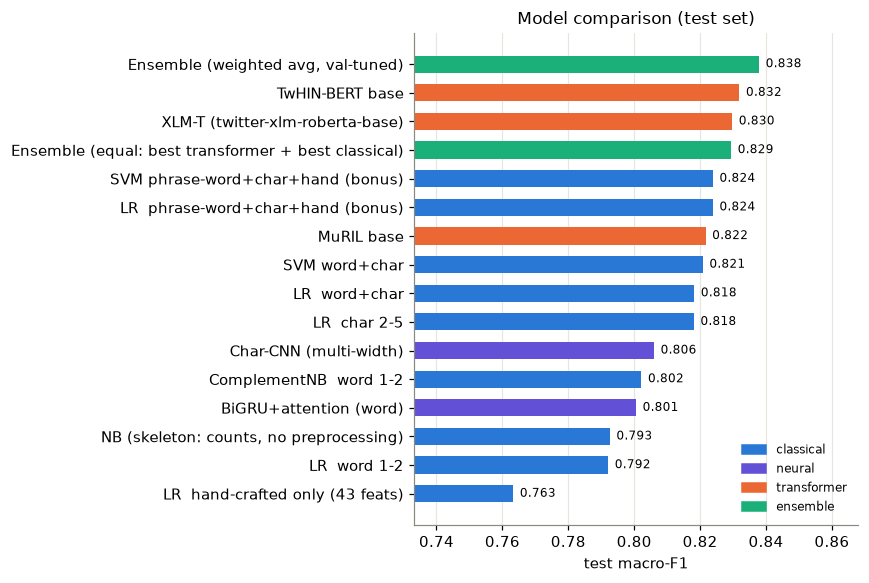

In [31]:
fam_col = {'classical': C0, 'neural': '#6250d6', 'transformer': C1, 'ensemble': '#1baf7a'}
f2 = final.sort_values('macro-F1')
fig, ax = plt.subplots(figsize=(8, 5.4))
ax.barh(f2.index, f2['macro-F1'], color=[fam_col[f] for f in f2.family], height=0.6)
for i, v in enumerate(f2['macro-F1']): ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=8)
ax.set_xlim(max(0.6, f2['macro-F1'].min() - 0.03), f2['macro-F1'].max() + 0.03); ax.grid(axis='y', visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in fam_col.items()], frameon=False, fontsize=8, loc='lower right')
ax.set_xlabel('test macro-F1'); ax.set_title('Model comparison (test set)'); plt.tight_layout(); plt.show()

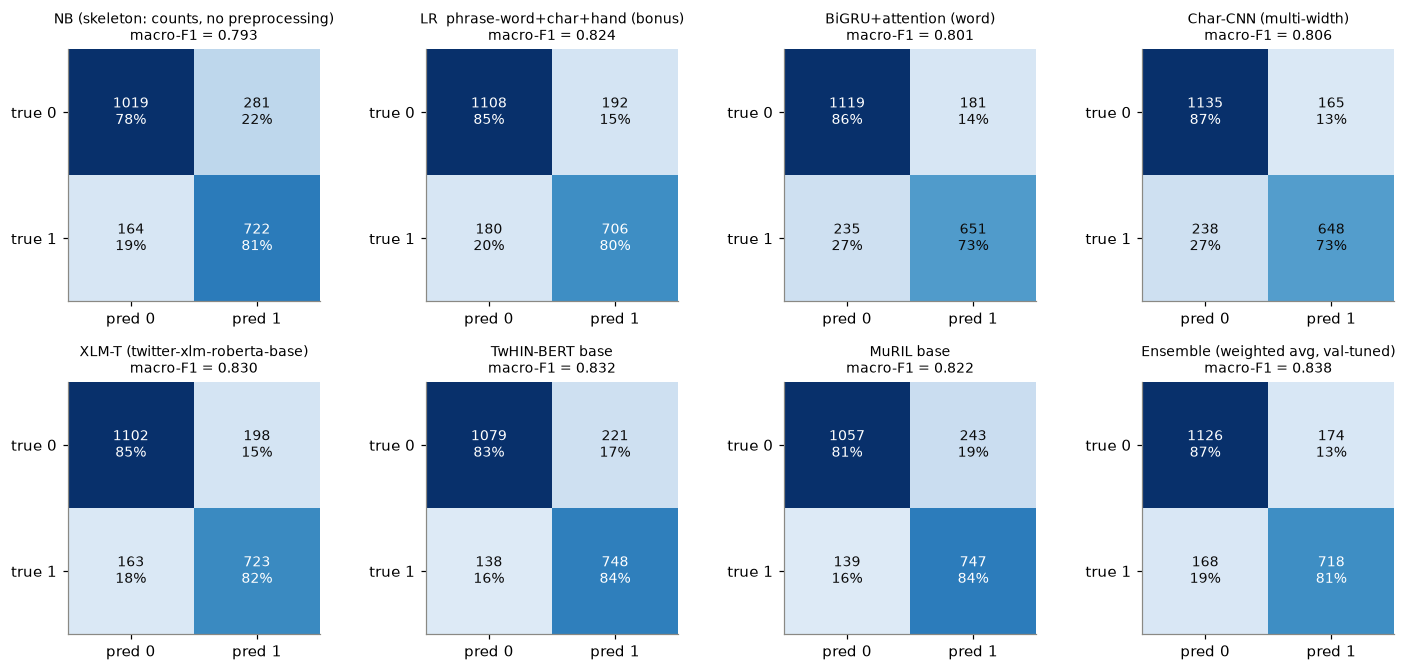

Model selected on validation: Ensemble (weighted avg, val-tuned)
               precision    recall  f1-score   support

non-sarcastic     0.8702    0.8662    0.8682      1300
    sarcastic     0.8049    0.8104    0.8076       886

     accuracy                         0.8435      2186
    macro avg     0.8376    0.8383    0.8379      2186
 weighted avg     0.8437    0.8435    0.8436      2186



In [32]:
main_models = ['NB (skeleton: counts, no preprocessing)', 'LR  phrase-word+char+hand (bonus)', 'BiGRU+attention (word)', 'Char-CNN (multi-width)'] + \
              [nm for nm, _, _ in TRANSFORMERS] + ['Ensemble (weighted avg, val-tuned)']
plot_cms(main_models, ncols=4)
best_name = final.index[0]
print('Model selected on validation:', best_name)
print(classification_report(y_te, PREDS[best_name], target_names=['non-sarcastic', 'sarcastic'], digits=4))

## 13. Emoji counterfactual: do the trained models actually rely on emojis?

The ablation in Section 8 *retrained* models without emojis. Here we take the **trained** models and delete the emojis from the **test** posts at inference time,
then measure (i) the macro-F1 change and (ii) how many predictions flip, restricted to posts that contain emojis.
A large flip rate means the model's decision depends on the emojis.

In [33]:
emo_mask = test_df.text.str.contains(EMOJI_RE).values
test_noemo = test_df.text.map(lambda t: re.sub(r'\s+', ' ', EMOJI_RE.sub(' ', t)).strip()).values

rows = []
for nm in ['LR  word+char', 'LR  phrase-word+char+hand (bonus)']:
    p0 = fitted[nm].predict(Xte); p1 = fitted[nm].predict(test_noemo)
    rows.append((nm, p0, p1))
for nm in TF_NOEMO:   # transformers: emoji-deleted test predictions were computed at the best epoch during fine-tuning
    rows.append((nm, PREDS[nm], (TF_NOEMO[nm] > 0.5).astype(int)))
cf = []
for nm, p0, p1 in rows:
    cf.append({'model': nm, 'macro-F1 (emoji posts, original)': f1_score(y_te[emo_mask], p0[emo_mask], average='macro'),
               'macro-F1 (emoji posts, emojis deleted)': f1_score(y_te[emo_mask], p1[emo_mask], average='macro'),
               'predictions flipped': (p0[emo_mask] != p1[emo_mask]).mean(),
               'sarcastic→non flips': ((p0 == 1) & (p1 == 0))[emo_mask].mean(),
               'non→sarcastic flips': ((p0 == 0) & (p1 == 1))[emo_mask].mean()})
print(f'{emo_mask.sum()} of {len(test_df)} test posts contain emojis')
pd.DataFrame(cf).set_index('model').style.format('{:.3f}')

1715 of 2186 test posts contain emojis


,"macro-F1 (emoji posts, original)","macro-F1 (emoji posts, emojis deleted)",predictions flipped,sarcastic→non flips,non→sarcastic flips
model,,,,,
LR word+char,0.800,0.747,0.166,0.000,0.166
LR phrase-word+char+hand (bonus),0.807,0.783,0.097,0.025,0.072
XLM-T (twitter-xlm-roberta-base),0.814,0.802,0.049,0.012,0.037
TwHIN-BERT base,0.815,0.810,0.029,0.003,0.026
MuRIL base,0.806,0.800,0.035,0.000,0.035


## 14. Error analysis

We analyze the errors of the model selected on validation. Each misclassified post is automatically tagged with linguistic phenomena,
which gives error rates per phenomenon. Then we read individual errors and comment on them.

In [34]:
NEG = re.compile(r'(?:^|\s)(نہیں|نہ|مت|نا)(?:\s|$)')
PRAISE = re.compile('|'.join(LEX['praise']))
def phenomena(t):
    tags = []
    if EMOJI_RE.search(t): tags.append('emoji')
    if re.search('[A-Za-z]{2,}', t): tags.append('code-mixed')
    if NEG.search(t): tags.append('negation')
    if PRAISE.search(t): tags.append('praise-word')
    if re.search(r'[?؟]', t): tags.append('question')
    if re.search(r'(\w)\1{2,}|(?:ہا){2,}', t): tags.append('elongation')
    if re.search(r"``|''|\"|“|”", t): tags.append('scare-quotes')
    if len(t.split()) <= 5: tags.append('very short (≤5 words)')
    if any(w in t for w in LEX['politics']): tags.append('political')
    if any(w in t for w in LEX['religion']): tags.append('religious')
    return tags

ea = test_df.copy()
ea['pred'] = PREDS[best_name]
ea['p_sarc'] = PROBS[best_name][1] if best_name in PROBS else np.nan
ea['error'] = ea.pred != ea.label
ea['tags'] = ea.text.map(phenomena)
ea['fp'] = (ea.pred == 1) & (ea.label == 0); ea['fn'] = (ea.pred == 0) & (ea.label == 1)

rows = []
for tag in sorted({t for ts in ea.tags for t in ts}):
    m = ea.tags.map(lambda ts: tag in ts)
    rows.append({'phenomenon': tag, 'test posts': int(m.sum()), 'error rate': ea.loc[m, 'error'].mean(),
                 'error rate (without)': ea.loc[~m, 'error'].mean(), 'FP share of errors': ea.loc[m & ea.error, 'fp'].mean()})
print(f'overall error rate of {best_name}: {ea.error.mean():.1%}  (FP {ea.fp.sum()}, FN {ea.fn.sum()})')
pd.DataFrame(rows).set_index('phenomenon').sort_values('error rate', ascending=False).style.format(
    {'error rate': '{:.1%}', 'error rate (without)': '{:.1%}', 'FP share of errors': '{:.0%}'}).background_gradient(subset=['error rate'], cmap='Oranges')

overall error rate of Ensemble (weighted avg, val-tuned): 15.6%  (FP 174, FN 168)


,test posts,error rate,error rate (without),FP share of errors
phenomenon,,,,
political,356,18.5%,15.1%,91%
negation,531,17.9%,14.9%,55%
question,95,16.8%,15.6%,81%
emoji,1715,15.9%,14.9%,46%
code-mixed,361,13.0%,16.2%,70%
praise-word,130,12.3%,15.9%,69%
scare-quotes,91,12.1%,15.8%,64%
religious,218,11.0%,16.2%,50%
elongation,62,8.1%,15.9%,20%


In [35]:
# 14 errors for close reading: the most confident false positives / false negatives plus random ones
err = ea[ea.error].copy()
err['confidence'] = np.where(err.pred == 1, err.p_sarc, 1 - err.p_sarc)
pick = pd.concat([err[err.fp].nlargest(4, 'confidence'), err[err.fn].nlargest(4, 'confidence'),
                  err[err.fp].drop(err[err.fp].nlargest(4, 'confidence').index).sample(3, random_state=7),
                  err[err.fn].drop(err[err.fn].nlargest(4, 'confidence').index).sample(3, random_state=7)])
pick = pick.assign(type=np.where(pick.fp, 'FP (pred sarcastic)', 'FN (pred non-sarcastic)'))
pick.insert(0, 'id', [f'E{i + 1}' for i in range(len(pick))])
pick[['id', 'text', 'label', 'pred', 'p_sarc', 'type', 'tags']].style.format({'p_sarc': '{:.2f}'}).hide(axis='index')

id,text,label,pred,p_sarc,type,tags
E1,اوآئی سی پر تنقید کرنے والے بتائیں کہ کشمیر پر اس نے کتنا جاندار موقف پیش کیا، حافظ طاہر اشرفی https://t.co/iAqKQT2KEz,0,1,0.95,FP (pred sarcastic),['code-mixed']
E2,"یہ سفارشی سرکاری تنخواہ پر جج صاحب پر تنقید کر رہا ہے, بیٹا پہلے بڑے ہو جاؤ, https://t.co/o7FfBAzkFf",0,1,0.94,FP (pred sarcastic),"['code-mixed', 'praise-word']"
E3,@SK_Tanoli_ حکومت اگر خان کی ھو تو سب ٹھیک ھے اگر #آلشریف کی حکومت ھو تو تب تعریف جیو پر اور تنقید ARY پر باقی سب same 🤣🤣 دونوں حکومتوں میں بس جیو اور ARY کا فرق ھے 🤣🤣,0,1,0.94,FP (pred sarcastic),"['emoji', 'code-mixed', 'praise-word', 'political']"
E4,@Sumairawn آپ کا تنقید کسی کے بنائے ہوئے کتوں پر ہے میں تنقید بنانے والوں پر کرتا ہوں جب اپنی انا کیلئے ملک پر قبضہ کر سکتے ہیں تو ملک کے حاطر ان سیاستدانوں کو ٹھیک کیوں نہیں کرتے اب آپ بھاگ جاؤ گے دانت دیکھا کر 😁😁😁😱 https://t.co/O6MWFuEOpT,0,1,0.94,FP (pred sarcastic),"['emoji', 'code-mixed', 'negation']"
E5,صلی اللہ علیہ وآلہ وسلّم🌹🌹🌹🌹🌹,1,0,0.02,FN (pred non-sarcastic),"['emoji', 'very short (≤5 words)', 'religious']"
E6,السلام عليكم۔۔۔ جیوندے روو۔۔۔ آمین۔۔۔ کی حال نے سونڑیو۔۔۔ 😘😍😘😍,1,0,0.02,FN (pred non-sarcastic),"['emoji', 'praise-word', 'religious']"
E7,پاکستان پائندہ باد 🇵🇰💚 شب بخیر ❤️,1,0,0.02,FN (pred non-sarcastic),['emoji']
E8,🍃🍃🍃🍃 آپ بھی,1,0,0.02,FN (pred non-sarcastic),"['emoji', 'very short (≤5 words)']"
E9,جمعرات کی بریانی آئی ہے پاڑو قسم کی مرچیلی ہے 😐,0,1,0.61,FP (pred sarcastic),['emoji']
E10,کیپٹن صفدر کی گرفتاری اور آئی جی سندھ کے اغواہ کی انکوائری جسٹس قاضی فائز عیسی سے کروائی جائے 👇 مولانا فضل الرحمان,0,1,0.65,FP (pred sarcastic),"['emoji', 'praise-word', 'political']"


### Commentary on the misclassified examples

The model is the val-selected ensemble (XLM-T 0.4 + TwHIN-BERT 0.4 + MuRIL 0.2, threshold 0.57). `p_sarc` is the ensemble's probability of "sarcastic".
Phenomenon tags are heuristic (keyword and regex based) and only approximate.

| id | Gold → pred | Phenomenon | Commentary |
|---|---|---|---|
| E1 | 0 → 1 (0.95) | topic/keyword confound, rhetorical question | A news-style quote of a cleric defending the OIC (Organisation of Islamic Cooperation): "those criticising the OIC should say how *strong* a stance it took on Kashmir". It contains **تنقید** ("criticism"), one of the strongest sarcasm n-grams in the dataset (Section 3), probably a collection keyword, plus a URL (93% sarcastic in this data). The rhetorical question also *reads* ironically, so the label itself is debatable. |
| E2 | 0 → 1 (0.94) | contempt vs. sarcasm, keyword confound | "This nepotism hire on a government salary is criticising the judge; *son, grow up first*." The post is openly contemptuous, not ironic: it means what it says. The model conflates mockery and sarcasm, and تنقید plus the URL push it towards 1. |
| E3 | 0 → 1 (0.94) | ambiguous label, code-mixing | "If it's Khan's government all is fine; under the Sharifs, praise is on Geo and criticism on ARY… *same* 🤣🤣". This is ironic commentary on media bias with English tokens (ARY, same) and laughing emojis. **We would label it sarcastic**, so the gold label 0 is questionable. |
| E4 | 0 → 1 (0.94) | ambiguous label, emoji | A taunting reply ending "now you'll run away, showing your teeth 😁😁😁😱". This is taunting; whether taunting counts as sarcasm depends on the annotator, and the label is borderline. |
| E5 | 1 → 0 (0.02) | **label noise** | "Peace be upon him 🌹🌹🌹" is a religious salutation and nothing in it is sarcastic. The model is confidently right and the gold label is wrong. |
| E6 | 1 → 0 (0.02) | **label noise**, Punjabi code-mixing | A greeting in Punjabi written in Urdu script (جیوندے روو "live long", کی حال نے سونڑیو "how are you, dear ones") with 😘😍. It is sincere, so the label is wrong. |
| E7 | 1 → 0 (0.02) | **label noise** | "Long live Pakistan 🇵🇰💚, good night ❤️" is a sincere patriotic sign-off. |
| E8 | 1 → 0 (0.02) | context dependence | "🍃🍃🍃🍃 you too" is a reply whose meaning depends entirely on the parent tweet. Without that context, no text-only model (or human) can recover sarcasm. |
| E9 | 0 → 1 (0.61) | informal register, slang | "Thursday's biryani has arrived, the fiery kind 😐". This is a literal, mildly humorous complaint. The emoji is not the cause, since 😐 is only 28% sarcastic in the data. The low-confidence error comes from the joking, colloquial register and slang (پاڑو): **humor is not sarcasm**, but the two share surface style. |
| E10 | 0 → 1 (0.65) | topic confound | A factual news line: Maulana Fazl-ur-Rehman demands a judicial inquiry into Captain Safdar's arrest. Every named entity (Safdar, IG Sindh, Fazl) is strongly associated with satire in training, so the model reacts to the topic rather than the tone. |
| E11 | 0 → 1 (0.89) | insult vs. sarcasm, political slur | A crude political jab using لفافہ ("envelope", slang for a bribed journalist). It is insulting rather than ironic, but political lexicon plus insult features push it towards 1. |
| E12 | 1 → 0 (0.26) | self-deprecating irony, emoji, Punjabi | A final-semester student's lament ending with the Punjabi شالا کوئی مسکین وی نہ ہووے ("may no poor soul end up like this") and 😒😟. The sarcasm is self-directed and non-political, and the sad-face emojis (strongly non-sarcastic in training) pull the prediction to 0. |
| E13 | 1 → 0 (0.40) | extended irony / analogy | "Every family has a child the mother praises for eating everything patiently and gratefully. Lahore is that child of Pakistan 😉". The irony lies in the analogy (Lahore silently putting up with neglect) and needs world knowledge. The 😉 cue alone is not enough. |
| E14 | 1 → 0 (0.56) | irony needing event knowledge, religious vocabulary | "Who knew prayers at Fatima Jinnah's mausoleum are answered so quickly". The irony depends on a news event the reader is expected to know. Religious vocabulary (دعائیں, قبول) pulls towards 0, and the probability is just below the 0.57 threshold. |

**Patterns across the errors**

1. **Label noise is a real ceiling.** The most confident false negatives (E5–E8, p = 0.02) are posts labeled sarcastic that clearly are not. This matches the 646 texts found with both labels in Section 2. Some of the reported "error" is annotation error.
2. **Topic and collection confounds cause most false positives.** 91% of errors on political posts are false positives. Words like تنقید, mentions, URLs and politician names predict "sarcastic" in this dataset regardless of tone (E1, E2, E10, E11).
3. **Mockery, contempt and insult are confused with sarcasm** (E2, E4, E11). Sarcasm says the opposite of what it means; an insult means exactly what it says. Neither the models nor, apparently, the annotators separate the two consistently.
4. **Irony that needs context or world knowledge is missed** (E8, E13, E14), especially when it is non-political and so does not match the dominant sarcastic topic.
5. **Emojis help on average but can mislead** (E12: sad faces in self-deprecating sarcasm), and **humor in general is confused with sarcasm** (E9).
6. **Code-mixing** (Punjabi in Urdu script in E6 and E12, English tokens in E3) is handled reasonably well: code-mixed posts have a *lower* error rate (13.0% vs 16.2%), likely helped by the multilingual subword vocabularies. Very short posts are the easiest (7.3% error).
7. **Negation.** Posts with negation (نہیں, نہ, مت) have a higher error rate (17.9% vs 14.9%), consistent with negation reversing polarity in ways a bag-of-cues model cannot track.

## 15. Report summary

### Data preparation
* The CSV has 20,060 rows. We dropped 105 missing texts and 56 missing labels, and ignored about 17 orphan texts in spill-over columns.
* **Duplicates:** 4,742 rows (24%) repeat an earlier text, 76% of them sarcastic, and **646 texts carry both labels**. The skeleton's random split therefore put **32.7% of test rows verbatim into train**, so its 0.775 score mixes memorization (92.5% accuracy on consistent leaked rows) with unresolvable label conflicts (57.6% on conflicting ones).
* We de-duplicated, removed the conflicting texts, and split the 14,567 unique posts into stratified **70/15/15** train/val/test sets (10,196 / 2,185 / 2,186). Class balance is 59.4% non-sarcastic and 40.6% sarcastic.
* We found and **masked label-revealing hashtags** (`#sarcasm`, `#طنز`, `#satire`; 98–100% sarcastic), an artifact of hashtag-based collection.

### Preprocessing and features
* **Urdu-aware normalization:** NFC; Arabic→Urdu letter variants (ي→ی, ك→ک, ه→ہ); diacritics and zero-width characters removed; digits unified.
* **Social-media signals turned into tokens** instead of deleted: URL, USER, HASHTAG, ELONG, LAUGH, MULTIPUNCT, ELLIPSIS, scare quotes, and five emoji modes.
* **Tokenization:** whitespace word n-grams plus `char_wb` 2–5 n-grams. Character n-grams compensate for Urdu's frequently omitted spaces and spelling variation.
* **Bonus feature engineering:**
  * 43 hand-crafted features: Urdu praise, political, religious, promotional, poetry, insult, negation and question lexicons; emoji-group counts; and incongruity features such as a praise word with a laughing emoji.
  * **PMI phrase detection** that learns about 1,200 multi-word expressions on the training split, e.g. عمران_خان, آرمی_چیف, آمین_ثم.

### Models
| Family | Models |
|---|---|
| Classical | Multinomial / Complement NB, logistic regression, linear SVM on TF-IDF word, char, phrase and hand-crafted features; C tuned on validation |
| Neural (from scratch) | BiGRU + attention + max-pool (word level); multi-width char-CNN (kernels 2–6); class-weighted loss, early stopping on validation |
| Transformers (fine-tuned) | XLM-T (Twitter XLM-R), TwHIN-BERT (multilingual Twitter BERT), MuRIL (Indic + transliterated); 4 epochs, lr 2–3e-5, best epoch on validation |
| Ensemble | weighted average of probabilities; weights and threshold chosen on validation |

### Results (test set, n = 2,186; selection by validation)
| Model | val macro-F1 | Accuracy | F1 non-sarc. | F1 sarc. | **Test macro-F1** |
|---|---|---|---|---|---|
| **Ensemble (XLM-T + TwHIN-BERT + MuRIL)** | **0.830** | **0.844** | **0.868** | **0.808** | **0.838** |
| TwHIN-BERT base | 0.816 | 0.836 | 0.857 | 0.807 | 0.832 |
| XLM-T | 0.817 | 0.835 | 0.859 | 0.800 | 0.830 |
| LR phrase-word + char + hand-crafted (best classical) | 0.810 | 0.830 | 0.856 | 0.792 | 0.824 |
| MuRIL base | 0.814 | 0.825 | 0.847 | 0.796 | 0.822 |
| SVM word + char | 0.797 | 0.826 | 0.850 | 0.791 | 0.821 |
| Char-CNN | 0.787 | 0.816 | 0.849 | 0.763 | 0.806 |
| BiGRU + attention | 0.794 | 0.810 | 0.843 | 0.758 | 0.801 |
| Skeleton NB (counts, no preprocessing), leak-free split | 0.792 | 0.796 | 0.821 | 0.764 | 0.793 |

Per-class precision and recall for every model are in Section 12, and the confusion matrices are plotted there. The ensemble makes 174 false positives and 168 false negatives.

### Main findings
1. **Transformers win, but by a modest margin.** The best single transformer beats the best TF-IDF model by only about 0.008 macro-F1. The dominant signals are lexical and topical (political satire vs. religious, poetic or promotional posts), which TF-IDF captures well.
   * Transformers mainly improve **sarcastic-class recall**.
   * Twitter-domain pretraining (TwHIN-BERT, XLM-T) beats the Indic-focused MuRIL.
   * Ensembling the three transformers adds another +0.006.
2. **Neural models trained from scratch are weaker than TF-IDF.** With 10k examples there is too little data to learn good embeddings. Pretraining is what makes deep models worthwhile here.
3. **Emojis.**
   * Emojis alone give 0.657 macro-F1.
   * Removing them never helps (it is the worst text setting in the ablation), but their marginal gain is small because they are largely redundant with the text.
   * The emoji counterfactual shows that **TF-IDF models depend on emojis far more than transformers do**. Deleting emojis at test time flips 16.6% of LR word+char predictions (all towards "sarcastic", because the model learned that hearts and flowers mean non-sarcastic and that emoji-free posts lean sarcastic), but only 2.9–4.9% for the transformers.
   * MuRIL is effectively emoji-blind (100% `[UNK]`) yet still competitive.
4. **Urdu-aware preprocessing helps TF-IDF consistently** (+0.006, 5/5 folds), mainly through URL/mention/hashtag handling. Character n-grams beat word n-grams. Hand-crafted features give a consistent gain (+0.0045, 5/5 folds); PMI phrases are neutral on their own.
5. **Label-hashtag leakage** would have inflated scores by about 0.004. Duplicate leakage in the naive split distorts evaluation even more.

### Limitations
* Label noise, including clearly mislabeled religious and greeting posts.
* Topic confounding between politics and sarcasm, which means part of what every model learns is genre rather than pragmatics.
* No conversational context (replies like E8 are unresolvable).
* A single random seed for the neural and transformer models.

### Reproducibility
* Run all cells in order from the `NLP/` folder. The seed is fixed (42).
* Transformer predictions are cached in `artifacts/`; set `FORCE_RETRAIN_TRANSFORMERS = True` to retrain, which takes about 1.5 h on an Apple M4 Pro GPU (MPS).
* Checkpoints are loaded from `hf_models/` if present, otherwise downloaded from the Hugging Face Hub.
* Requirements: pandas, scikit-learn, torch, transformers, matplotlib.

### Acknowledgements and references
* **Dataset:** Urdu sarcastic tweets dataset provided by the course (DS5007).
* **Pretrained models:**
  * Barbieri, Espinosa-Anke and Camacho-Collados (2022), *XLM-T: Multilingual Language Models in Twitter for Sentiment Analysis and Beyond*, LREC.
  * Zhang et al. (2023), *TwHIN-BERT: A Socially-Enriched Pre-trained Language Model for Multilingual Tweet Representations*, KDD.
  * Khanuja et al. (2021), *MuRIL: Multilingual Representations for Indian Languages*.
  * Conneau et al. (2020), *Unsupervised Cross-lingual Representation Learning at Scale* (XLM-R).
* **Methods:**
  * Riloff et al. (2013), *Sarcasm as Contrast between a Positive Sentiment and Negative Situation*, EMNLP: incongruity features.
  * Mikolov et al. (2013), *Distributed Representations of Words and Phrases and their Compositionality*, NeurIPS: phrase score.
* **Libraries:** scikit-learn, PyTorch, Hugging Face Transformers, pandas, matplotlib.
* **AI assistance:** this notebook's code, experiments and draft explanations were developed with the assistance of Claude (Anthropic), an AI assistant. All numbers are produced by executing this notebook.

## 16. Saved artifacts and reuse

Everything needed to reproduce or reuse the results without long training is written to `artifacts/`:

| Path | Content |
|---|---|
| `artifacts/*.npz` | transformer validation/test probabilities and per-epoch history (this is what lets Section 10 skip the ~1.2 h fine-tuning) |
| `artifacts/models/splits/{train,val,test}.csv` | the exact cleaned, de-duplicated splits |
| `artifacts/models/*.joblib` | fitted classical pipelines (preprocessing + TF-IDF + features + classifier) |
| `artifacts/models/bigru_word.pt`, `charcnn.pt` | best-epoch neural-network weights, vocabulary and training history (re-used by Section 9 unless `FORCE_RETRAIN_NN = True`) |
| `artifacts/models/results_test.csv`, `ablation_cv.csv`, `predictions_test.csv` | result tables and per-post test predictions of every model |
| `artifacts/models/ensemble.json` | ensemble members, weights and threshold |
| `artifacts/models/transformers/` | fine-tuned transformer weights, only if `SAVE_TRANSFORMER_WEIGHTS = True` during a re-train |

The pickled pipelines refer to functions defined in this notebook (`preprocess`, `HandFeatures`, `PhraseMerger`…).
To load them in a new session, first run the definition cells (Sections 1, 3, 5, 6 and 7), then call `joblib.load`.

In [36]:
import joblib
def slug(s): return re.sub(r'[^a-z0-9]+', '_', s.lower()).strip('_')

saved_cl = {}
for nm in ['LR  phrase-word+char+hand (bonus)', 'SVM phrase-word+char+hand (bonus)', 'LR  word+char', 'SVM word+char', 'LR  char 2-5']:
    path = os.path.join(SAVE_DIR, slug(nm) + '.joblib'); joblib.dump(fitted[nm], path, compress=3); saved_cl[nm] = path

final.to_csv(os.path.join(SAVE_DIR, 'results_test.csv'))
abl.to_csv(os.path.join(SAVE_DIR, 'ablation_cv.csv'), index=False)
pd.DataFrame({'text': test_df.text, 'label': y_te, **{f'pred | {k}': v for k, v in PREDS.items()},
              **{f'p_sarc | {k}': v[1] for k, v in PROBS.items()}}).to_csv(os.path.join(SAVE_DIR, 'predictions_test.csv'), index=False)
json.dump({'members': weights, 'threshold': float(th), 'val_macro_f1': float(best_ens[0]),
           'transformers': {nm: hf_id for nm, hf_id, _ in TRANSFORMERS}},
          open(os.path.join(SAVE_DIR, 'ensemble.json'), 'w'), ensure_ascii=False, indent=2)

for f in sorted(os.listdir(SAVE_DIR)):
    p = os.path.join(SAVE_DIR, f)
    if os.path.isfile(p): print(f'{f:55s} {os.path.getsize(p) / 1e6:7.1f} MB')

ablation_cv.csv                                             0.0 MB
bigru_word.pt                                               8.6 MB
charcnn.pt                                                  0.9 MB
ensemble.json                                               0.0 MB
lr_char_2_5.joblib                                          0.8 MB
lr_phrase_word_char_hand_bonus.joblib                       1.4 MB
lr_word_char.joblib                                         1.4 MB
predictions_test.csv                                        0.8 MB
results_test.csv                                            0.0 MB
svm_phrase_word_char_hand_bonus.joblib                      1.4 MB
svm_word_char.joblib                                        1.4 MB


In [37]:
# Reuse demo: load the best classical model from disk and classify new posts (no training needed)
clf_loaded = joblib.load(saved_cl['LR  phrase-word+char+hand (bonus)'])
assert (clf_loaded.predict(Xte) == PREDS['LR  phrase-word+char+hand (bonus)']).all()   # identical to the in-memory model

def predict_sarcasm(texts, model=clf_loaded):
    p = model.predict_proba(list(texts))[:, 1]
    return pd.DataFrame({'text': list(texts), 'P(sarcastic)': p.round(3), 'prediction': np.where(p > 0.5, 'sarcastic', 'non-sarcastic')})

predict_sarcasm(['واہ کیا بات ہے حکومت کی، مہنگائی پھر بڑھ گئی 😂😂',
                 'جزاک اللہ خیر، اللہ آپ کو ہمیشہ خوش رکھے 🌹',
                 'نواز شریف صاحب لندن سے قوم کی خدمت کر رہے ہیں 😉',
                 'آج موسم بہت اچھا ہے، شام کو چائے پئیں گے'])

,text,P(sarcastic),prediction
0,واہ کیا بات ہے حکومت کی، مہنگائی پھر بڑھ گئی 😂😂,0.756,sarcastic
1,جزاک اللہ خیر، اللہ آپ کو ہمیشہ خوش رکھے 🌹,0.016,non-sarcastic
2,نواز شریف صاحب لندن سے قوم کی خدمت کر رہے ہیں 😉,0.916,sarcastic
3,آج موسم بہت اچھا ہے، شام کو چائے پئیں گے,0.132,non-sarcastic


In [38]:
# Reloading a saved neural network (example: char-CNN)
ck = torch.load(os.path.join(SAVE_DIR, 'charcnn.pt'), weights_only=False)
cnn = CharCNN(len(ck['vocab']) + 2); cnn.load_state_dict(ck['state_dict']); cnn.eval()
def encode_chars(texts, vocab=ck['vocab'], max_len=300):
    return torch.tensor([([vocab.get(c, 1) for c in NN_PP(s)][:max_len] + [0] * max_len)[:max_len] for s in texts])
with torch.no_grad():
    p = cnn(encode_chars(test_df.text)).softmax(-1)[:, 1].numpy()
print(f"reloaded char-CNN (best epoch {ck['best_epoch']}): test macro-F1 = {f1_score(y_te, p > 0.5, average='macro'):.4f}")

reloaded char-CNN (best epoch 6): test macro-F1 = 0.8060
